# Developing a machine learning model for predicting length of stay in hospital

In this project, we will develop a machine learning model to predict the length of stay (LOS) for patients in a hospital. The LOS is an important metric for hospital management as it helps in resource allocation and improving patient care.

## Data Collection
We will use a dataset that contains patient information, including demographics, medical history, and hospital stay details. The dataset can be sourced from hospital records or publicly available healthcare datasets.

## Data Preprocessing
1. **Data Cleaning**: Handle missing values, remove duplicates, and correct any inconsistencies in the data.
2. **Feature Engineering**: Create new features that may be relevant for predicting LOS, such as the number of previous hospital visits, severity of illness, and comorbidities.
3. **Encoding Categorical Variables**: Convert categorical variables into numerical format using techniques like one-hot encoding or label encoding.
4. **Feature Scaling**: Normalize or standardize the features to ensure that they are on the same scale, which can improve the performance of certain machine learning algorithms.

## Model Selection
We will experiment with several machine learning algorithms to find the best model for predicting LOS. Some of the algorithms we will consider include:
- Linear Regression
- Decision Trees
- Random Forest 
- Gradient Boosting Machines
- Support Vector Machines

## Model Training and Evaluation
1. **Train-Test Split**: Split the dataset into training and testing sets to evaluate the performance of the model.
2. **Model Training**: Train the selected models on the training data.
3. **Model Evaluation**: Evaluate the models using appropriate metrics such as Mean Absolute Error (MAE), Mean Squared Error (MSE), and R-squared (R²) to assess their performance in predicting LOS.
4. **Hyperparameter Tuning**: Use techniques like Grid Search or Random Search to optimize the hyperparameters of the models for better performance.
5. **Cross-Validation**: Implement cross-validation to ensure that the model's performance is consistent across different subsets of the data.## Model Deployment
Once we have selected the best-performing model, we will deploy it in a production environment. This involves:
1. **Model Serialization**: Save the trained model using a format like Pickle or Joblib for later use.




In [1]:
# libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Encoding libraries
import logging
import miceforest as mf
import pickle
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

## data 

In [2]:
dar1 = pd.read_csv("/home/kyomukama/ACE/camonet/ML_Rerun/mice_results/imputed_data_clean_ward.csv")

In [3]:
dar1.head()

,name_of_rrh,age,sex,num_infection_sites,referral,ward,cormobid_condition,antibiotics_prescribed,growth1,Resistance,length_hosp_stay
0,Arua,36.0,Female,2,No,Gynaecology,No,Yes,No,No,13.0
1,Arua,57.0,Female,3,No,Orthopaedic,No,Yes,Yes,Yes,46.0
2,Arua,8.0,Female,2,No,Gynaecology,No,Yes,Yes,Yes,1.0
3,Arua,1.0,Male,3,Yes,Paediatric,No,Yes,No,No,4.0
4,Arua,21.0,Female,1,Yes,Gynaecology,No,Yes,Yes,Yes,3.0


In [38]:
dar1['antibiotics_prescribed'].value_counts()

antibiotics_prescribed
Yes    1314
No      450
Name: count, dtype: int64

In [4]:
cam1 = pd.read_csv("/home/kyomukama/ACE/camonet/ml (NEW)/data_no_encoded_wards.csv")

In [5]:
cam1.head()

,name_of_rrh,age,sex,Infection_Site_1,Infection_Site_2,Infection_Site_3,referral,ward,antib_prior_admi,sympt_dura,...,growth1,first_organism,sec_organism,third_organism,Resistance,Antibioitic_aft_cul_1,Antibioitic_aft_cul_2,complications,treatment_outcome,length_hosp_stay
0,Arua,6.0,Male,Brain,No infection,No infection,Yes,Pediatric ward,Unknown,< 1 week,...,No,No pathogen,No pathogen,No pathogen,No,No antibiotic precibed,No antibiotic precibed,No,Cured/recovered,12.0
1,Arua,13.0,Male,Lungs,Systemic,No infection,Yes,Medical ward,Unknown,1- < 2 weeks,...,No,No pathogen,No pathogen,No pathogen,No,No antibiotic precibed,No antibiotic precibed,No,Cured/recovered,8.0
2,Arua,11.0,Male,Systemic,No infection,No infection,No,Pediatric ward,Unknown,< 1 week,...,No,No pathogen,No pathogen,No pathogen,No,No antibiotic precibed,No antibiotic precibed,Yes,Cured/recovered,14.0
3,Arua,18.0,Male,Surgical_site,No infection,No infection,Yes,Surgical ward,Unknown,< 1 week,...,Yes,Citrobacter spp,No pathogen,No pathogen,Yes,No antibiotic precibed,No antibiotic precibed,Yes,Cured/recovered,0.0
4,Arua,17.0,Female,Surgical_site,No infection,No infection,Yes,Maternity ward,Unknown,< 1 week,...,Yes,Escherichia coli,No pathogen,No pathogen,Yes,Chloramphenicol,No antibiotic precibed,Yes,Cured/recovered,10.0


In [39]:
cam1.columns

Index(['hospital', 'age', 'sex', 'Infection_Site_1', 'Infection_Site_2',
       'Infection_Site_3', 'referral', 'ward_encoded', 'antib_prior_admi',
       'sympt_dura', 'hiv_status', 'intubated', 'cormobid_condition',
       'Prescribed_antib_1', 'Prescribed_antib_2', 'Prescribed_antib_3',
       'Prescribed_antib_4', 'Prescribed_antib_5', 'organism_isolated',
       'growth1', 'first_organism', 'sec_organism', 'third_organism',
       'Resistance', 'Antibioitic_aft_cul_1', 'Antibioitic_aft_cul_2',
       'complications', 'treatment_outcome', 'length_hosp_stay'],
      dtype='object')

In [6]:
cam1.shape

(596, 29)

In [7]:
cam1.rename(columns={'ward': 'ward_encoded'}, inplace=True)
cam1.rename(columns={'name_of_rrh' : "hospital"}, inplace=True)

In [8]:
ward = cam1[["ward_encoded",'hospital']]

# Analysis and Visualization

In [9]:
daring = pd.read_csv("/home/kyomukama/ACE/Patient outcomes/HLOS/ML_developement/Data/ml_data_encoded.csv")

In [10]:
daring.shape

(1764, 11)

In [11]:
camonet = pd.read_csv("/home/kyomukama/ACE/Patient outcomes/HLOS/ML_developement/Data/test_data.csv")

In [12]:
camonet.shape

(596, 11)

In [13]:
camonet1 = pd.concat([camonet, ward], axis=1)

In [14]:
camonet1.head()

,age,num_infection_sites,sex,referral,cormobid_condition,antibiotics_prescribed,growth1,Resistance,name_of_rrh,ward,length_hosp_stay,ward_encoded,hospital
0,6.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,7.0,12.0,Pediatric ward,Arua
1,13.0,2.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,4.0,8.0,Medical ward,Arua
2,11.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,7.0,14.0,Pediatric ward,Arua
3,18.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,9.0,0.0,Surgical ward,Arua
4,17.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,0.0,3.0,10.0,Maternity ward,Arua


In [15]:
camonet1.drop(columns=['ward', 'name_of_rrh'], inplace=True)

In [16]:
camonet1.columns 

Index(['age', 'num_infection_sites', 'sex', 'referral', 'cormobid_condition',
       'antibiotics_prescribed', 'growth1', 'Resistance', 'length_hosp_stay',
       'ward_encoded', 'hospital'],
      dtype='object')

In [17]:
camonet1['length_hosp_stay'].isna().sum()

1

In [18]:
camonet1.rename(columns={'ward_encoded': 'ward'}, inplace=True)
camonet1.rename(columns={'hospital' : "name_of_rrh"}, inplace=True)

In [19]:
data = pd.concat([dar1, camonet1], axis=0)

In [20]:
pd.set_option('display.max_columns', None)
data.head()

,name_of_rrh,age,sex,num_infection_sites,referral,ward,cormobid_condition,antibiotics_prescribed,growth1,Resistance,length_hosp_stay
0,Arua,36.0,Female,2.0,No,Gynaecology,No,Yes,No,No,13.0
1,Arua,57.0,Female,3.0,No,Orthopaedic,No,Yes,Yes,Yes,46.0
2,Arua,8.0,Female,2.0,No,Gynaecology,No,Yes,Yes,Yes,1.0
3,Arua,1.0,Male,3.0,Yes,Paediatric,No,Yes,No,No,4.0
4,Arua,21.0,Female,1.0,Yes,Gynaecology,No,Yes,Yes,Yes,3.0


In [21]:
data['num_infection_sites'].value_counts()

num_infection_sites
1.0    1594
2.0     555
3.0     149
0.0      44
4.0      17
Name: count, dtype: int64

In [22]:
data.shape

(2360, 11)

In [23]:
data['ward'].value_counts()

ward
Medical                      546
Surgical                     476
Paediatric                   313
Surgical ward                224
Gynaecology                  171
Medical ward                 136
Pediatric ward                91
Orthopaedic                   81
ICU/HDU                       69
Maternity/Post-Natal ward     55
Maternity ward                55
NICU Unit                     53
Gyecology ward                34
ICU Unit                      30
NICU                          23
Orthopedic ward                3
Name: count, dtype: int64

In [24]:
dict = {
    "Gynaecology" : "Gynaecology",
    "Medical ward" : "Medical",
    "Pediatric ward" : "Pediatric",
    "Surgical ward" : "Surgical",
    "ICU Unit" : "ICU/HDU",
    "Maternity ward" : "Maternity/Post-Natal ward",
    "Gyecology ward" : "Gynaecology",
    "Orthopedic ward" : "Orthopedic",
    "NICU Unit" : "NICU",
    "Orthopaedic" : "Orthopedic",
    "Paediatric" : "Pediatric",
}

data['ward'] = data['ward'].replace(dict)

# Length of Hospital Stay

In [25]:
data['length_hosp_stay'].describe()

count    2359.000000
mean       30.827045
std        91.884122
min         0.000000
25%         7.000000
50%        15.000000
75%        29.000000
max      1843.000000
Name: length_hosp_stay, dtype: float64

In [26]:
# Drop rows where length_hosp_stay is still NaN after calculation
data.dropna(subset=['length_hosp_stay'], inplace=True)

In [27]:
data.shape

(2359, 11)

In [28]:
data['ward']

0                    Gynaecology
1                     Orthopedic
2                    Gynaecology
3                      Pediatric
4                    Gynaecology
                 ...            
591                    Pediatric
592    Maternity/Post-Natal ward
593    Maternity/Post-Natal ward
594    Maternity/Post-Natal ward
595                    Pediatric
Name: ward, Length: 2359, dtype: object

In [29]:
data.columns

Index(['name_of_rrh', 'age', 'sex', 'num_infection_sites', 'referral', 'ward',
       'cormobid_condition', 'antibiotics_prescribed', 'growth1', 'Resistance',
       'length_hosp_stay'],
      dtype='object')

In [30]:
data['name_of_rrh'].value_counts()

name_of_rrh
Lira       524
Mbarara    351
Arua       315
Kabale     299
Gulu       226
Jinja      202
Masaka     196
Mbale      177
Soroti      69
Name: count, dtype: int64

In [31]:
data.replace({'sex' : {1: 'Male', 0: 'Female'}}, inplace=True)

In [32]:
data.replace({'referral' : {1: 'Yes', 0: 'No'}}, inplace=True)

In [33]:
data.replace({'cormobid_condition' : {1: 'Yes', 0: 'No'}}, inplace=True)

In [34]:
data.replace({'antibiotics_prescribed' : {1: 'Yes', 0: 'No'}}, inplace=True)

In [35]:
data.replace({'growth1' : {1: 'Yes', 0: 'No'}}, inplace=True)

In [36]:
data.replace({'Resistance' : {1: 'Yes', 0: 'No'}}, inplace=True)

In [40]:
data['Resistance'].value_counts()

Resistance
No     1276
Yes    1082
Name: count, dtype: int64

# ML dataset

In [37]:
data.isna().sum()

name_of_rrh               0
age                       1
sex                       1
num_infection_sites       1
referral                  1
ward                      0
cormobid_condition        1
antibiotics_prescribed    1
growth1                   1
Resistance                1
length_hosp_stay          0
dtype: int64

In [79]:
data.dropna(inplace=True)

In [80]:
data.shape

(2358, 11)

In [81]:
data.value_counts()

name_of_rrh  age   sex     num_infection_sites  referral  ward                       cormobid_condition  antibiotics_prescribed  growth1  Resistance  length_hosp_stay
Mbarara      33.0  Female  2.0                  No        ICU/HDU                    No                  Yes                     No       No          117.0               3
Arua         36.0  Male    1.0                  No        Surgical                   No                  No                      Yes      Yes         53.0                3
Gulu         2.0   Female  3.0                  No        Pediatric                  No                  Yes                     No       No          10.0                3
Mbale        21.0  Female  2.0                  Yes       Gynaecology                No                  No                      Yes      No          48.0                2
Arua         9.0   Female  2.0                  No        Pediatric                  No                  Yes                     Yes      No     

In [82]:
data['ward'].value_counts()

ward
Surgical                     700
Medical                      681
Pediatric                    403
Gynaecology                  205
Maternity/Post-Natal ward    110
ICU/HDU                       99
Orthopedic                    84
NICU                          76
Name: count, dtype: int64

In [83]:
data.to_csv("/home/kyomukama/ACE/Patient outcomes/HLOS/ML_developement/Data/ml_data_encoded_combined.csv", index=False)

In [62]:
ml_data = data.copy()

In [63]:
ml_data.head()

,age,num_infection_sites,sex,referral,cormobid_condition,antibiotics_prescribed,growth1,Resistance,name_of_rrh,ward,length_hosp_stay
0,36.0,2.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,13.0
1,57.0,3.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,6.0,46.0
2,8.0,2.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0
3,1.0,3.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,7.0,4.0
4,21.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,3.0


In [64]:
ml_data.tail()

,age,num_infection_sites,sex,referral,cormobid_condition,antibiotics_prescribed,growth1,Resistance,name_of_rrh,ward,length_hosp_stay
591,27.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0,8.0,3.0,10.0
592,20.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,8.0,3.0,3.0
593,24.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,8.0,3.0,6.0
594,2.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0,8.0,7.0,8.0
595,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,21.0


In [65]:
ml_data.shape

(2359, 11)

In [66]:
ml_data.isna().sum()

age                       1
num_infection_sites       1
sex                       1
referral                  1
cormobid_condition        1
antibiotics_prescribed    1
growth1                   1
Resistance                1
name_of_rrh               1
ward                      1
length_hosp_stay          0
dtype: int64

In [67]:
ml_data.shape

(2359, 11)

In [ ]:
ml_data.to_csv

In [16]:
# Shuffle rows and reset the index
ml_data = ml_data.sample(frac=1).reset_index(drop=True)

In [17]:
# Set random seed for reproducibility
SEED = 1 
np.random.seed(SEED)

# Define target percentiles to identify rare cases
low_threshold = np.percentile(ml_data["length_hosp_stay"], 25)  # Lower quartile
high_threshold = np.percentile(ml_data["length_hosp_stay"], 75)  # Upper quartile

# Identify minority samples (e.g., extreme low & high values)
minority_samples = ml_data[(ml_data["length_hosp_stay"] <= low_threshold) | (ml_data["length_hosp_stay"] >= high_threshold)]

# Bootstrap resampling (with replacement) to balance the dataset
bootstrapped_minority = minority_samples.sample(n=len(ml_data), replace=True, random_state=SEED)

# Combine with the original dataset
imputed_data = pd.concat([ml_data, bootstrapped_minority])

# Shuffle the final dataset
imputed_data = imputed_data.sample(frac=1, random_state=SEED).reset_index(drop=True)

# Display the new balanced dataset
print(imputed_data.shape)


(4718, 11)


In [18]:
imputed_data.head()

,age,num_infection_sites,sex,referral,cormobid_condition,antibiotics_prescribed,growth1,Resistance,name_of_rrh,ward,length_hosp_stay
0,28.0,2.0,0.0,0.0,0.0,1.0,1.0,1.0,3.0,9.0,19.0
1,43.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,5.0,4.0,5.0
2,52.0,3.0,0.0,0.0,0.0,1.0,0.0,0.0,3.0,4.0,8.0
3,78.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,8.0,9.0,54.0
4,30.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0,7.0,1.0,4.0


In [19]:
X = imputed_data.drop(columns=['length_hosp_stay'])
y = imputed_data['length_hosp_stay']

In [20]:
y.dtypes

dtype('float64')

In [21]:
X.dtypes

age                       float64
num_infection_sites       float64
sex                       float64
referral                  float64
cormobid_condition        float64
antibiotics_prescribed    float64
growth1                   float64
Resistance                float64
name_of_rrh               float64
ward                      float64
dtype: object

In [22]:
cat_columns = X.select_dtypes(include='object').columns
cat_columns

Index([], dtype='object')

In [23]:
X.head

<bound method NDFrame.head of        age  num_infection_sites  sex  referral  cormobid_condition  \
0     28.0                  2.0  0.0       0.0                 0.0   
1     43.0                  1.0  0.0       0.0                 1.0   
2     52.0                  3.0  0.0       0.0                 0.0   
3     78.0                  1.0  0.0       1.0                 0.0   
4     30.0                  1.0  0.0       0.0                 0.0   
...    ...                  ...  ...       ...                 ...   
4713  36.0                  1.0  0.0       0.0                 1.0   
4714  14.0                  1.0  0.0       1.0                 1.0   
4715  18.0                  1.0  1.0       0.0                 0.0   
4716  67.0                  1.0  0.0       0.0                 0.0   
4717   9.0                  2.0  1.0       0.0                 0.0   

      antibiotics_prescribed  growth1  Resistance  name_of_rrh  ward  
0                        1.0      1.0         1.0         

# Correct datatypes of the different columns

In [24]:
X.dtypes

age                       float64
num_infection_sites       float64
sex                       float64
referral                  float64
cormobid_condition        float64
antibiotics_prescribed    float64
growth1                   float64
Resistance                float64
name_of_rrh               float64
ward                      float64
dtype: object

In [25]:
# Converting object columns 'category'
cols = ['sex', 'referral', 'cormobid_condition', 'antibiotics_prescribed', 'growth1', 'Resistance', 'ward', 'name_of_rrh']
X[cols] = X[cols].astype('category')

In [26]:
train_wards = set(X["ward"].unique())
train_wards

{0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, nan, -1.0}

In [27]:
ml_data = pd.concat([X, y], axis=1)
ml_data.head()

,age,num_infection_sites,sex,referral,cormobid_condition,antibiotics_prescribed,growth1,Resistance,name_of_rrh,ward,length_hosp_stay
0,28.0,2.0,0.0,0.0,0.0,1.0,1.0,1.0,3.0,9.0,19.0
1,43.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,5.0,4.0,5.0
2,52.0,3.0,0.0,0.0,0.0,1.0,0.0,0.0,3.0,4.0,8.0
3,78.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,8.0,9.0,54.0
4,30.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0,7.0,1.0,4.0


In [28]:
ml_data.shape

(4718, 11)

In [157]:
ml_data.dtypes

age                        float64
num_infection_sites        float64
sex                       category
referral                  category
cormobid_condition        category
antibiotics_prescribed    category
growth1                   category
Resistance                category
name_of_rrh               category
ward                      category
length_hosp_stay           float64
dtype: object

# Pycaret setup

In [158]:
from pycaret.regression import *

In [159]:
s = setup(data = ml_data, target = 'length_hosp_stay', session_id=123)

,Description,Value
0,Session id,123
1,Target,length_hosp_stay
2,Target type,Regression
3,Original data shape,"(4718, 11)"
4,Transformed data shape,"(4718, 30)"
5,Transformed train set shape,"(3302, 30)"
6,Transformed test set shape,"(1416, 30)"
7,Numeric features,2
8,Categorical features,8
9,Rows with missing values,0.0%


In [160]:
best = compare_models()

,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE,TT (Sec)
lightgbm,Light Gradient Boosting Machine,32.1097,7378.0483,82.9529,0.2598,1.2568,3.1084,0.3080
catboost,CatBoost Regressor,26.1560,5792.9730,72.1096,0.2414,1.1334,2.4946,4.1740
gbr,Gradient Boosting Regressor,32.8458,8413.0258,87.7931,0.0724,1.2962,3.3764,0.0710
en,Elastic Net,35.6705,12829.7841,108.4031,-0.0047,1.4276,4.1725,0.0310
huber,Huber Regressor,29.0784,13063.5228,109.1140,-0.0053,1.1110,1.7583,0.0460
lasso,Lasso Regression,35.9078,12650.0261,107.9399,-0.0116,1.3836,3.8431,0.2540
llar,Lasso Least Angle Regression,35.9077,12650.0287,107.9399,-0.0116,1.3836,3.8431,0.0310
omp,Orthogonal Matching Pursuit,35.6666,12885.5122,108.7030,-0.0142,1.4086,4.0647,0.0300
dummy,Dummy Regressor,36.8778,12995.6245,109.0586,-0.0144,1.4749,4.4894,0.0280
br,Bayesian Ridge,36.0541,12630.6522,107.9389,-0.0163,1.3664,3.6270,0.0340


# Data codebook

In [161]:
%run -i "Scripts/codebook.py"

Codebook generated successfully!


## Visualisations

In [162]:
%run -i "Scripts/visualizations.py"

Numeric variables: Index(['age', 'num_infection_sites', 'length_hosp_stay'], dtype='object')
Categorical variables: Index(['sex', 'referral', 'cormobid_condition', 'antibiotics_prescribed',
       'growth1', 'Resistance', 'name_of_rrh', 'ward'],
      dtype='object')

EDA visualization complete!
Plots saved in: Outputs/EDA_Visualizations


<Figure size 800x550 with 0 Axes>

# Machine Learning model development

In [163]:
ml_data.head()

,age,num_infection_sites,sex,referral,cormobid_condition,antibiotics_prescribed,growth1,Resistance,name_of_rrh,ward,length_hosp_stay
0,36.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,4.0,4.0,8.0
1,65.0,2.0,0.0,0.0,1.0,0.0,0.0,0.0,7.0,4.0,9.0
2,40.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,7.0,4.0,13.0
3,21.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,5.0,4.0,7.0
4,22.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,7.0,4.0,4.0


In [164]:
ml_data.rename(
    columns= {
        "age" : "Age at admission",
        "num_infection_sites" :"Number of anatomical sites with infection",
        "sex" : "Sex",
        "referral" : "Referral status",
        "cormobid_condition" : "Presence of any comorbidity",
        "antibiotics_prescribed" : "Antibiotics prescribed",
        "growth1" : "Culture growth",
        "Resistance" : "Antimicrobial resistance status",
        "name_of_rrh" : "Hospital",
        "ward" : "Admission ward",
        "length_hosp_stay" : "Length of hospital stay (days)"
    }, inplace=True
)

In [165]:
ml_data['Length of hospital stay (days)'].describe()

count    4718.000000
mean       36.604281
std       106.864466
min         0.000000
25%         5.000000
50%        14.000000
75%        39.000000
max      1843.000000
Name: Length of hospital stay (days), dtype: float64

In [166]:
ml_data.loc[ml_data['Length of hospital stay (days)'] > 60, ['Length of hospital stay (days)']]

,Length of hospital stay (days)
6,96.0
7,94.0
11,101.0
12,96.0
15,154.0
...,...
4694,385.0
4698,209.0
4705,64.0
4708,159.0


In [167]:
ml_data.drop(ml_data[ml_data['Length of hospital stay (days)'] > 60].index, inplace=True)
ml_data.reset_index(drop=True, inplace=True)

<Axes: xlabel='Length of hospital stay (days)', ylabel='Count'>

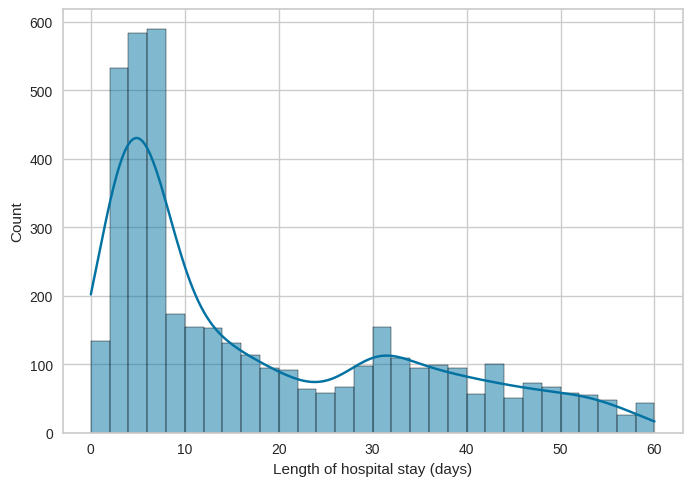

In [168]:
length_of_stay_dist = ml_data['Length of hospital stay (days)']

sns.histplot(length_of_stay_dist, bins=30, kde=True)

<Axes: xlabel='Length of hospital stay (days)', ylabel='Count'>

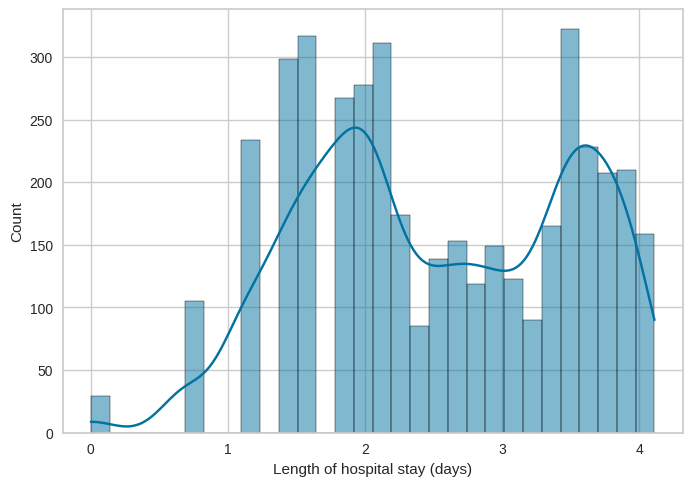

In [169]:
log_length_of_stay_dist = np.log1p(length_of_stay_dist)

sns.histplot(log_length_of_stay_dist, bins=30, kde=True)

In [170]:
# Run the ML pipeline
# %run -i "Scripts/machine_learning_pipeline.py"

In [171]:
ml_data.tail()

,Age at admission,Number of anatomical sites with infection,Sex,Referral status,Presence of any comorbidity,Antibiotics prescribed,Culture growth,Antimicrobial resistance status,Hospital,Admission ward,Length of hospital stay (days)
4157,2.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,8.0,7.0,1.0
4158,22.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,4.0,9.0,49.0
4159,18.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,2.0,4.0,2.0
4160,73.0,2.0,0.0,1.0,1.0,1.0,0.0,0.0,7.0,2.0,2.0
4161,38.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,3.0,3.0,43.0


In [172]:
ml_data.isna().sum()

Age at admission                             1
Number of anatomical sites with infection    1
Sex                                          1
Referral status                              1
Presence of any comorbidity                  1
Antibiotics prescribed                       1
Culture growth                               1
Antimicrobial resistance status              1
Hospital                                     1
Admission ward                               1
Length of hospital stay (days)               0
dtype: int64

In [173]:
ml_data.dropna(inplace=True)

RF best params: {'model__max_depth': None, 'model__min_samples_leaf': 2, 'model__n_estimators': 600}
XGB best params: {'model__colsample_bytree': 1.0, 'model__learning_rate': 0.05, 'model__max_depth': 5, 'model__min_child_weight': 5, 'model__n_estimators': 1000, 'model__subsample': 0.8}
LGBM best params: {'model__learning_rate': 0.05, 'model__n_estimators': 800, 'model__num_leaves': 63}
GB best params: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 500, 'model__subsample': 0.8}
ElasticNet best params: {'model__alpha': 0.001, 'model__l1_ratio': 0.2}
SVR best params: {'model__C': 5.0, 'model__epsilon': 0.05, 'model__kernel': 'rbf'}
CatBoost best params: {'model__depth': 6, 'model__iterations': 800, 'model__learning_rate': 0.05}
Saved base model: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/model_RF.joblib
Saved base model: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/model_XGB.joblib
Saved base model: /home/kyomukama/ACE/camonet/ML_Reru

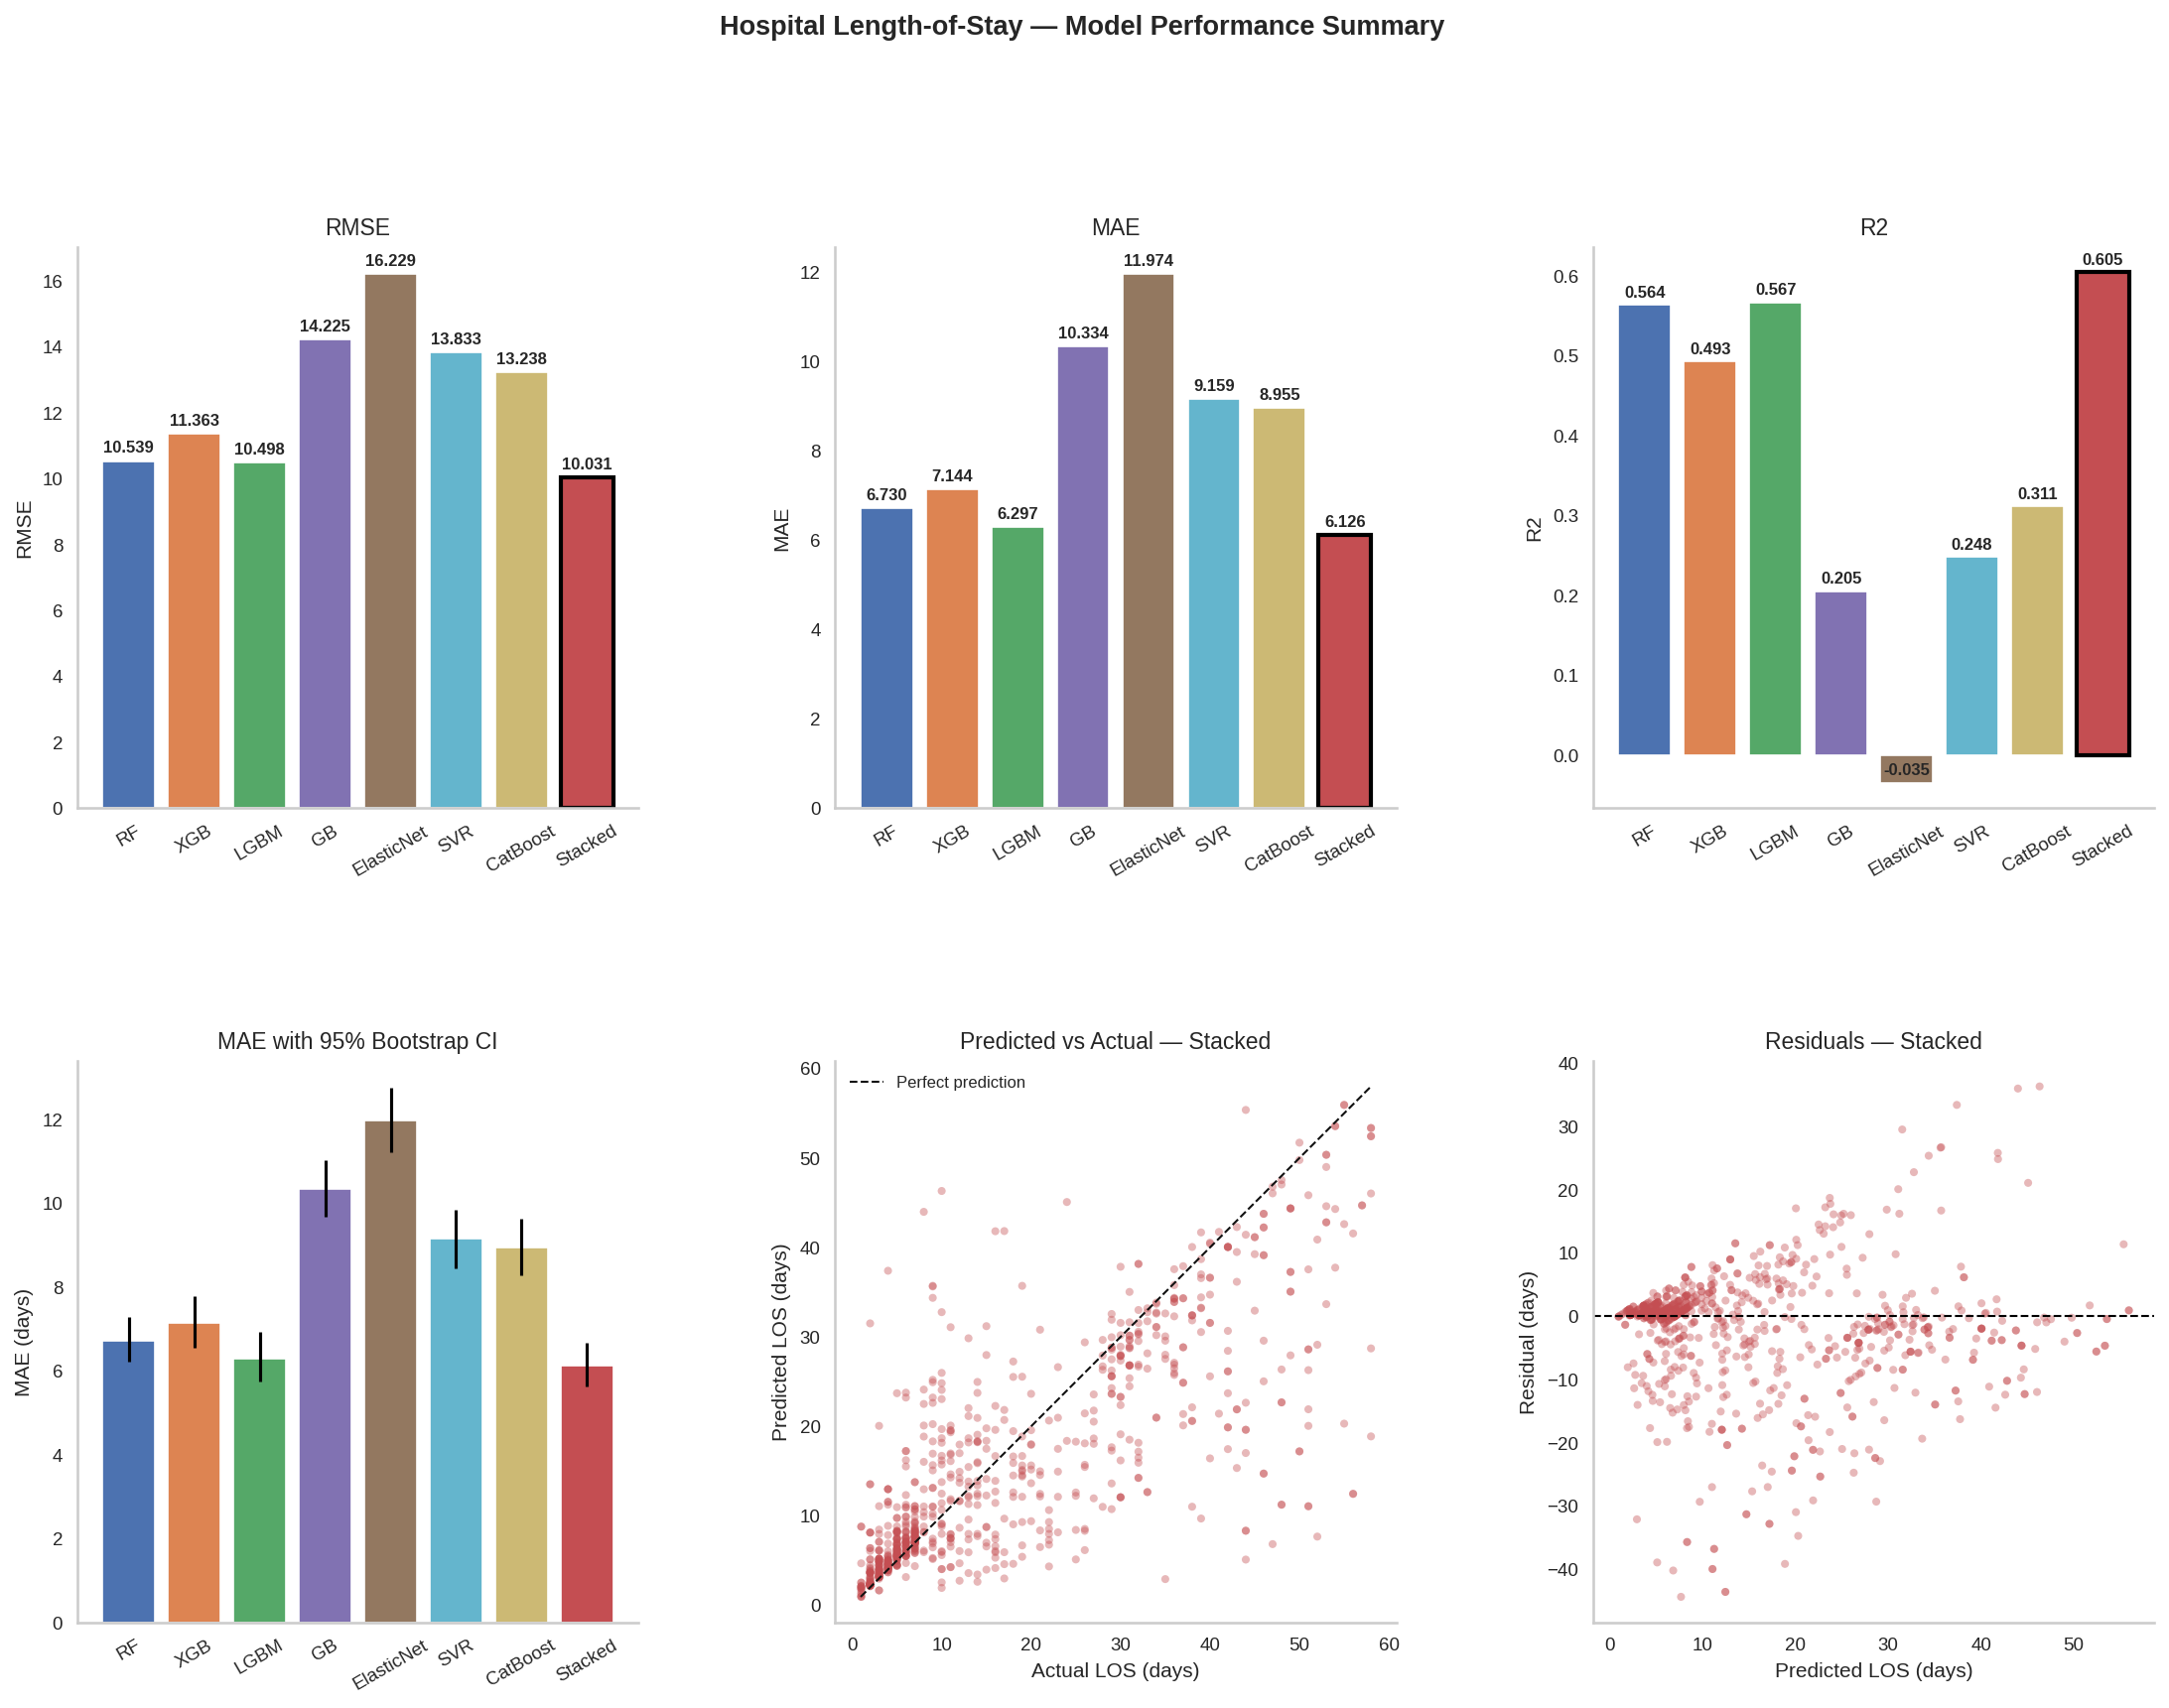

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/model_performance.png


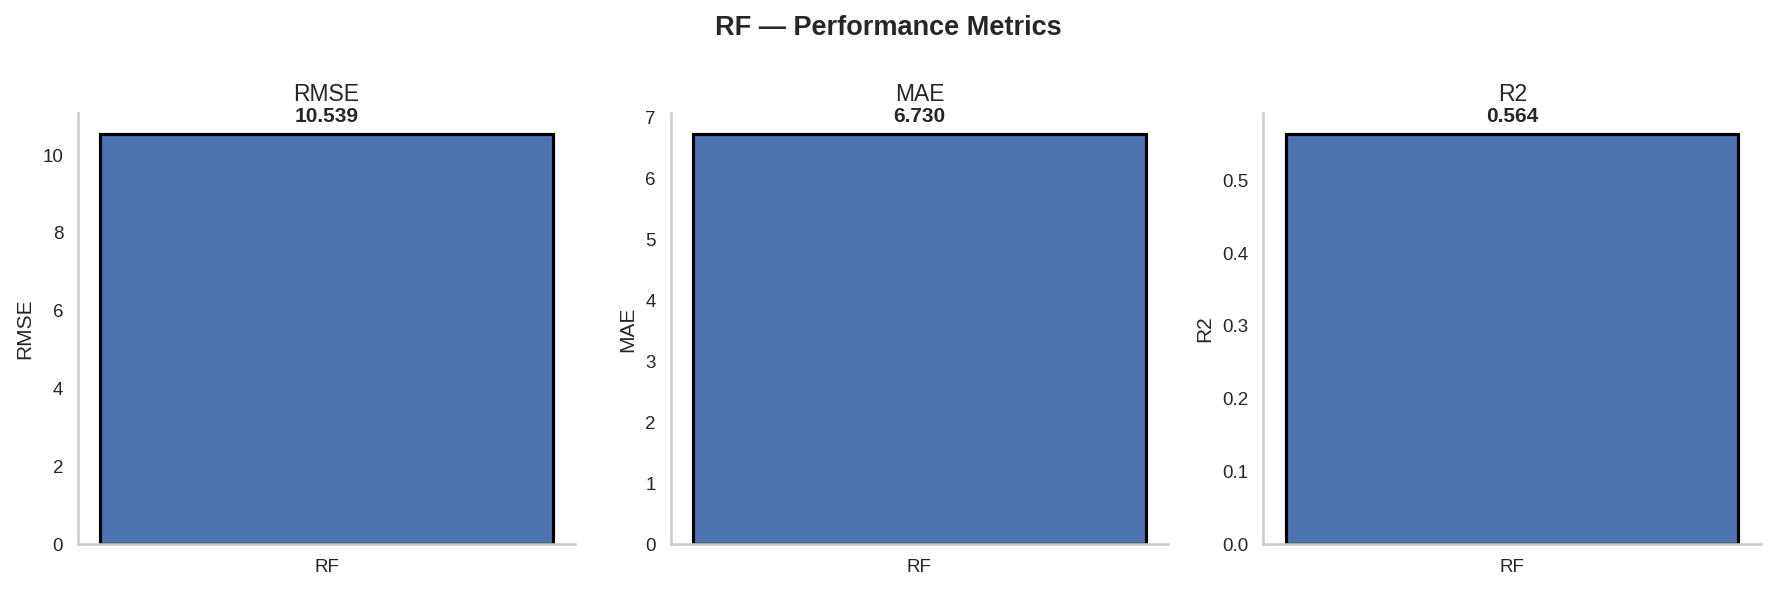

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/metrics_RF.png


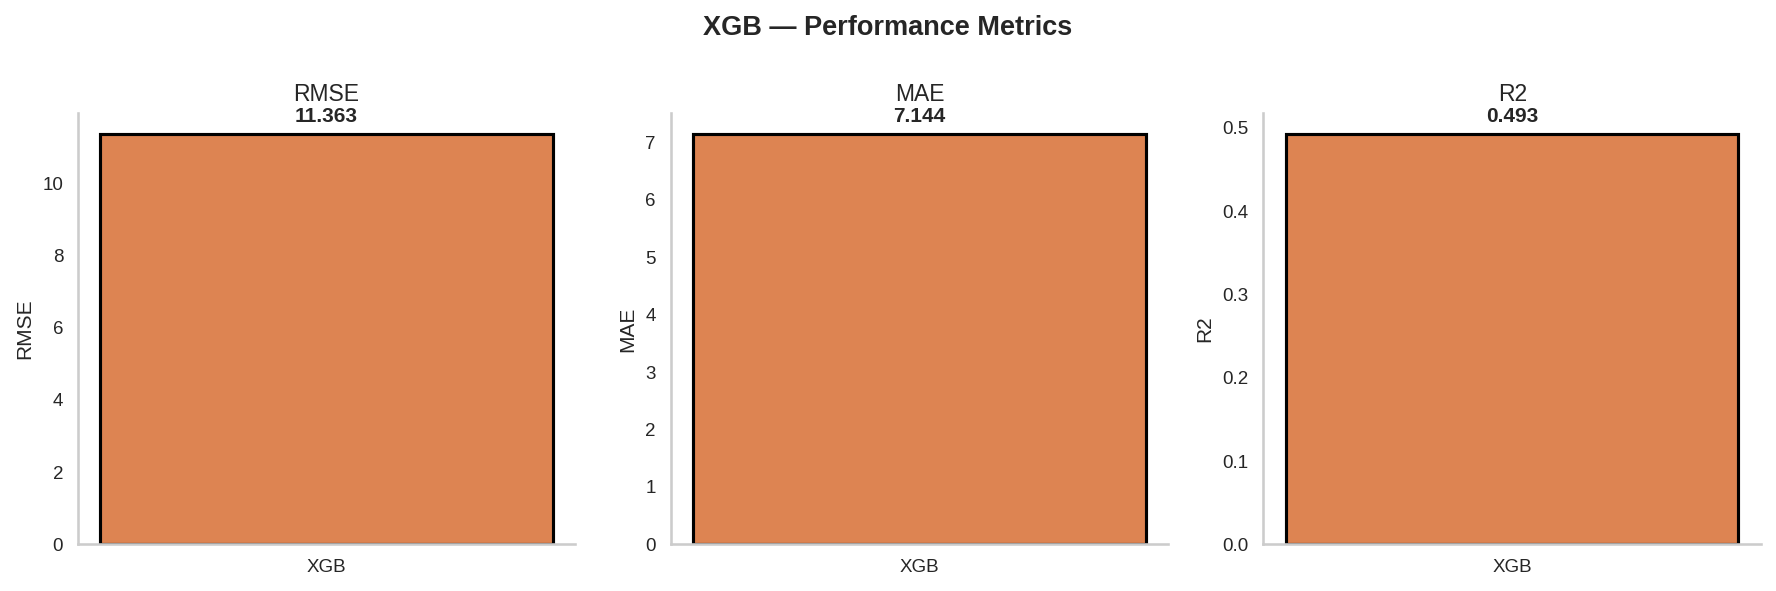

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/metrics_XGB.png


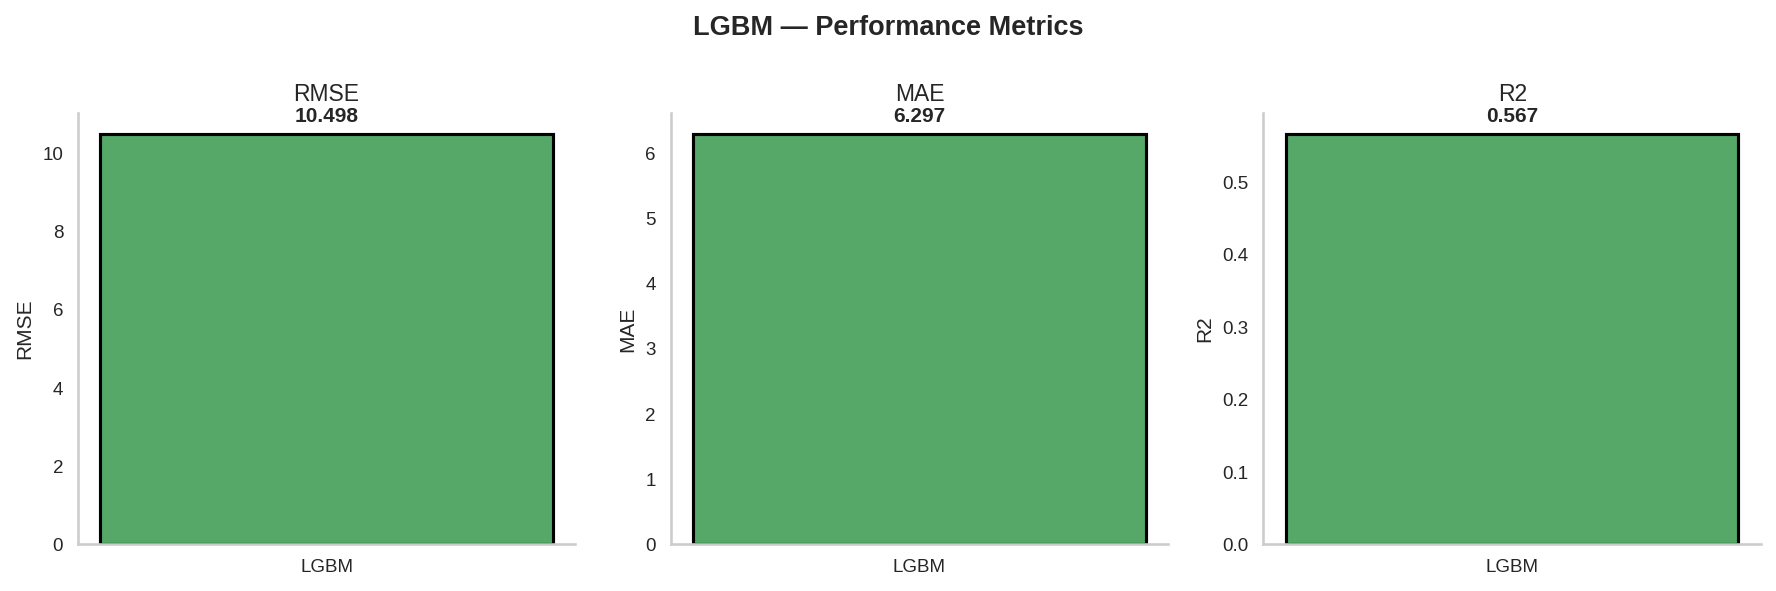

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/metrics_LGBM.png


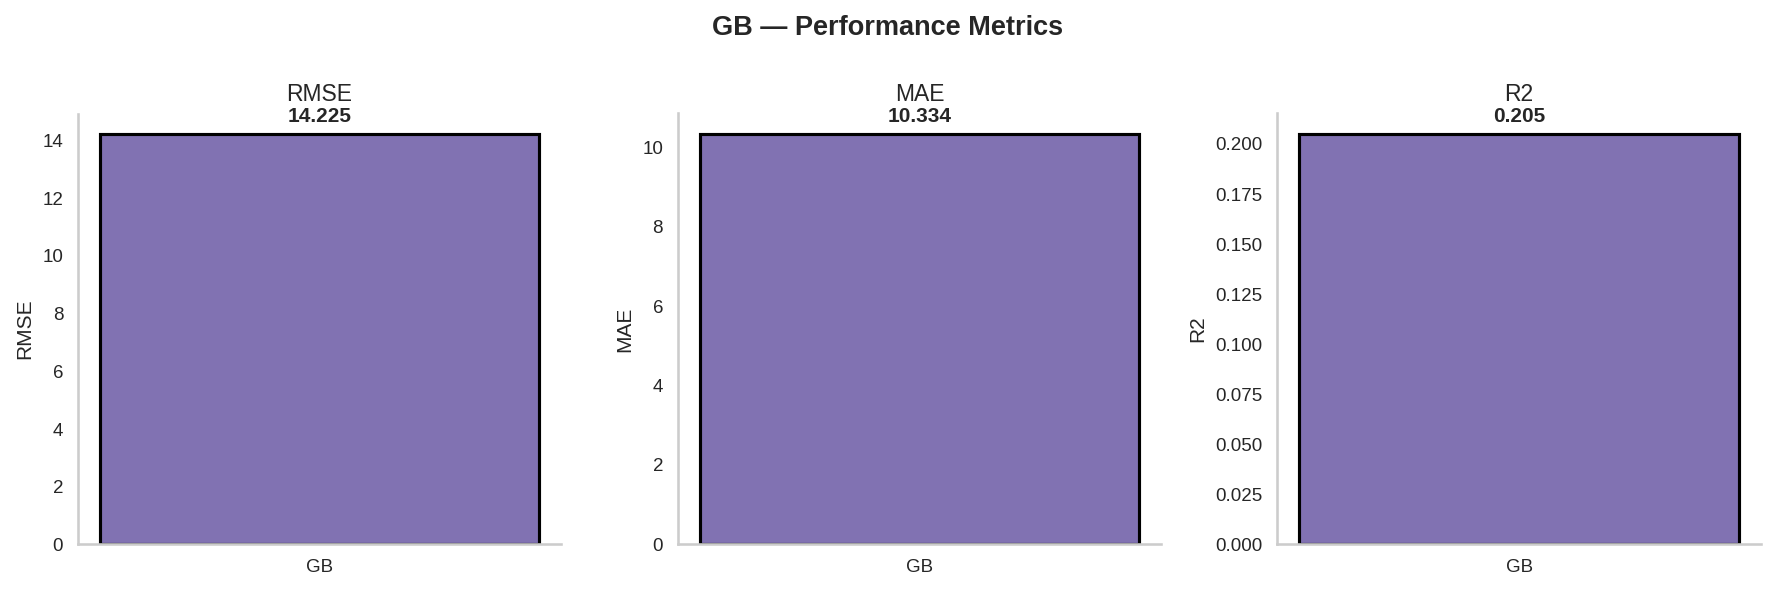

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/metrics_GB.png


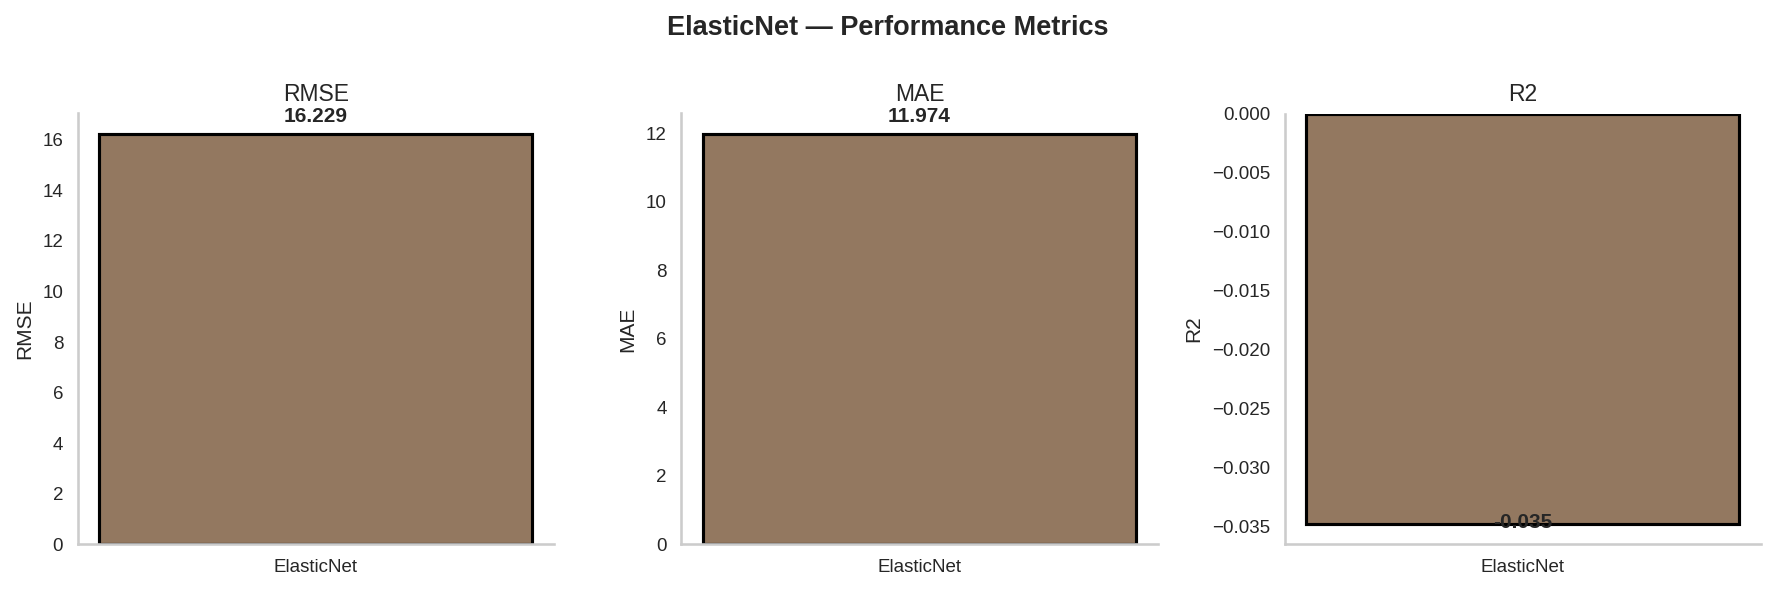

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/metrics_ElasticNet.png


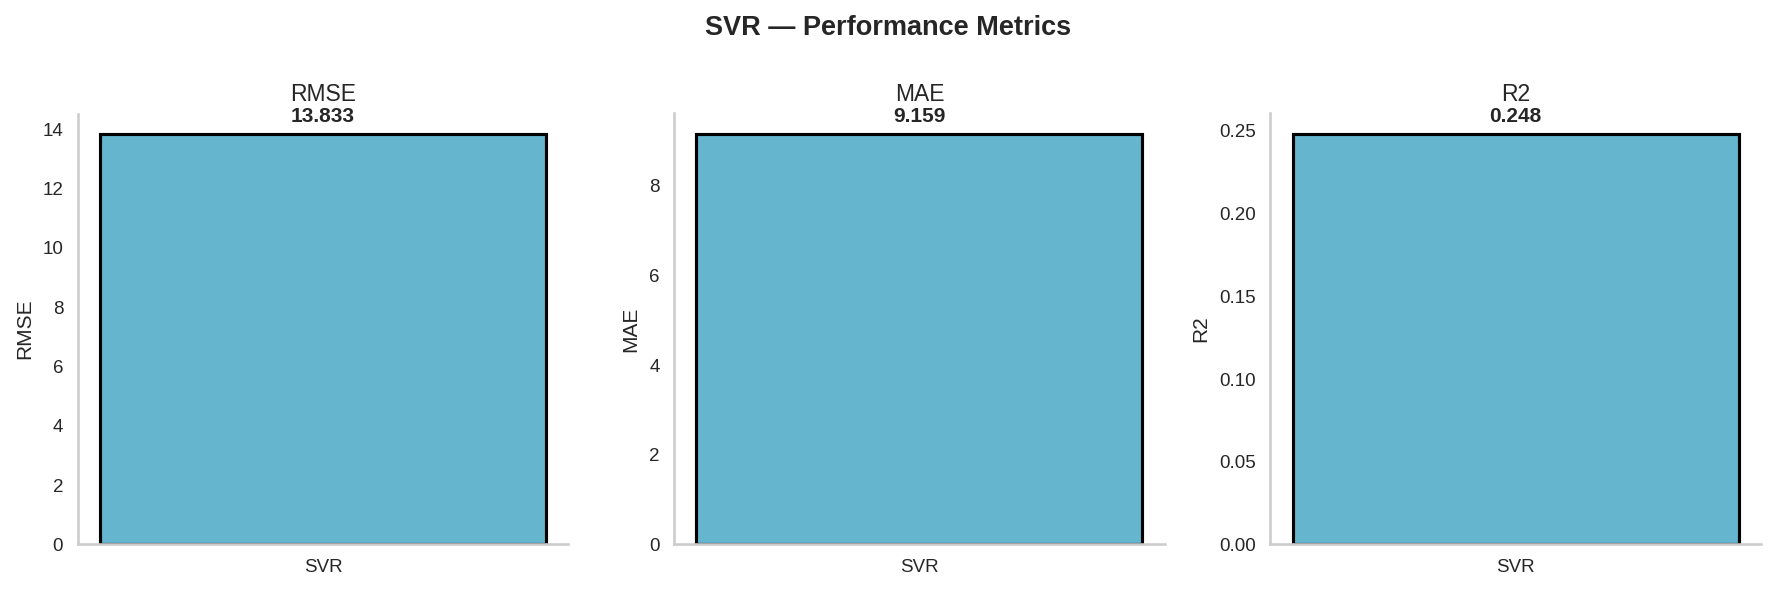

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/metrics_SVR.png


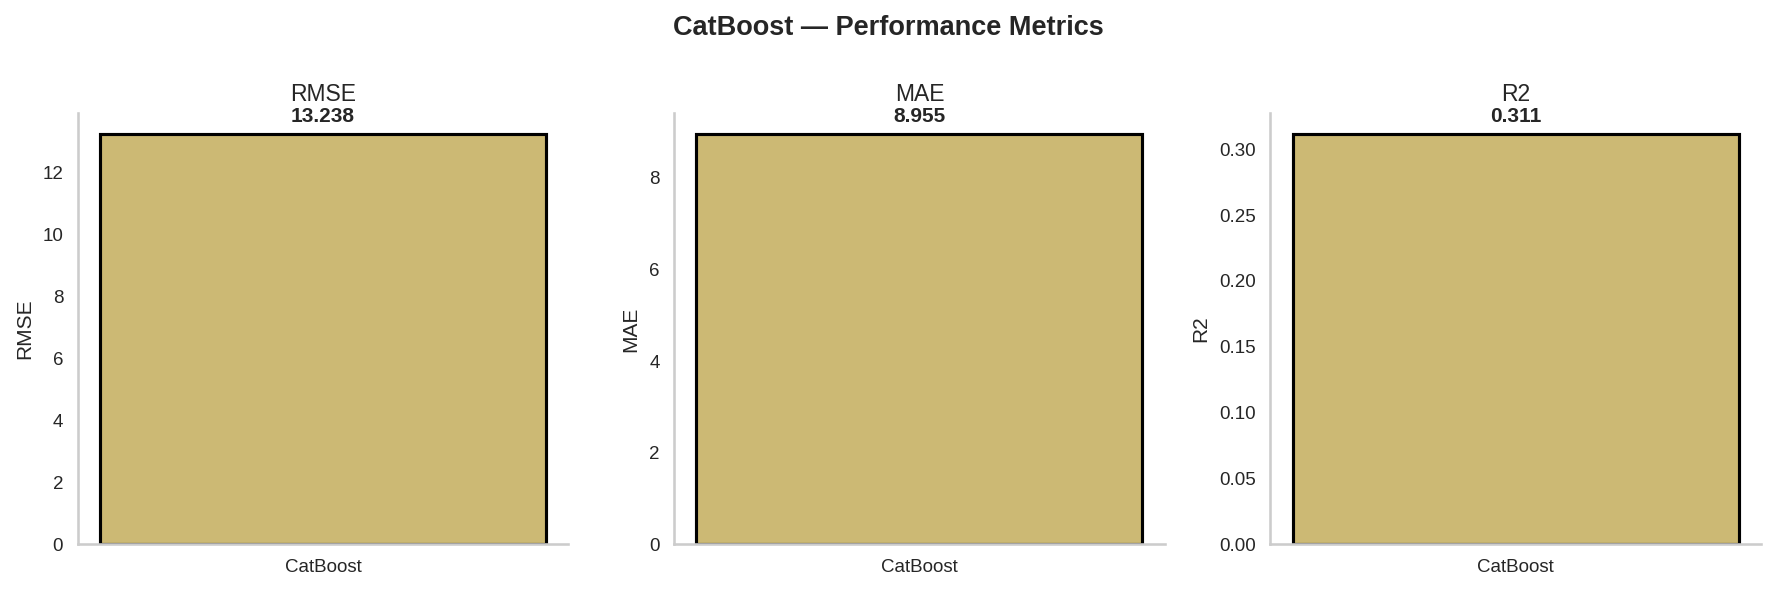

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/metrics_CatBoost.png


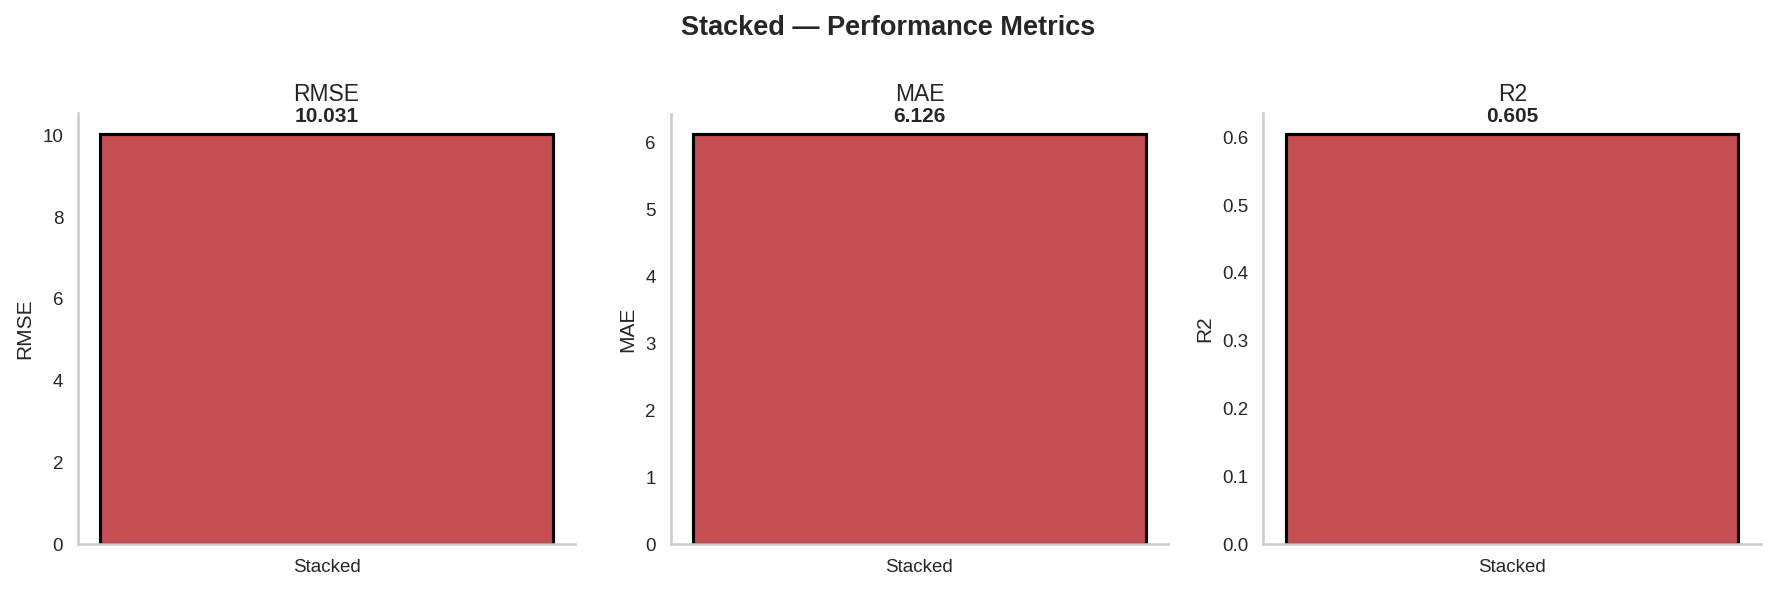

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/metrics_Stacked.png


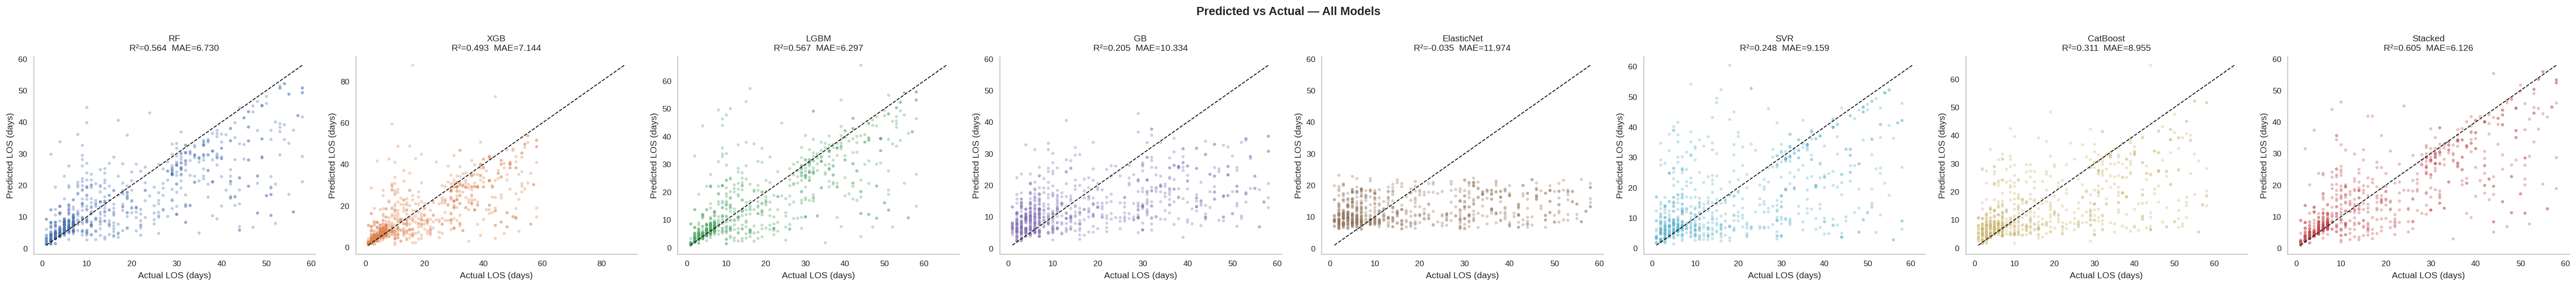

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/predicted_vs_actual_all.png


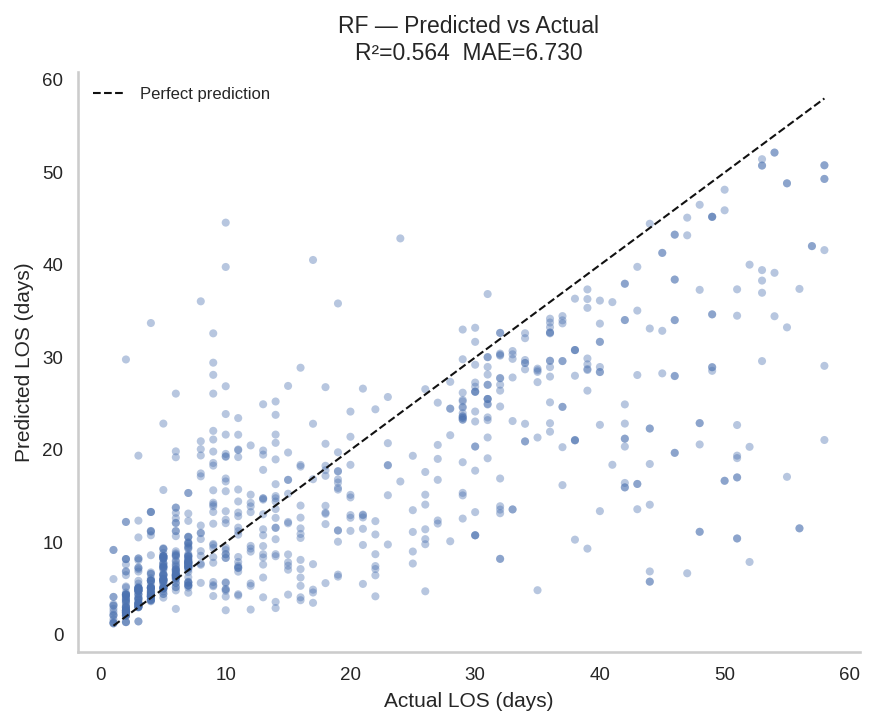

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/predicted_vs_actual_RF.png


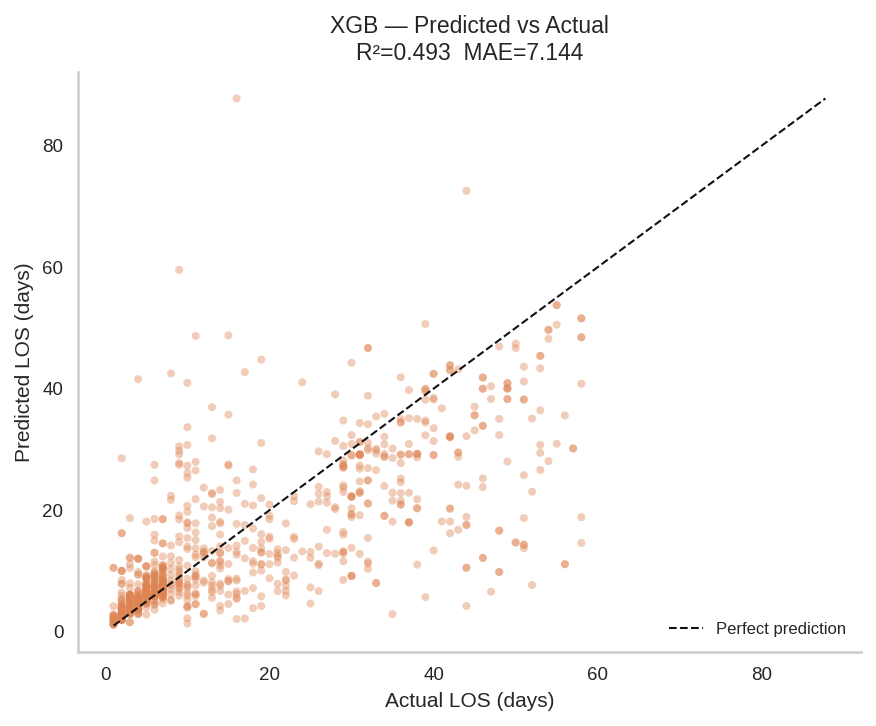

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/predicted_vs_actual_XGB.png


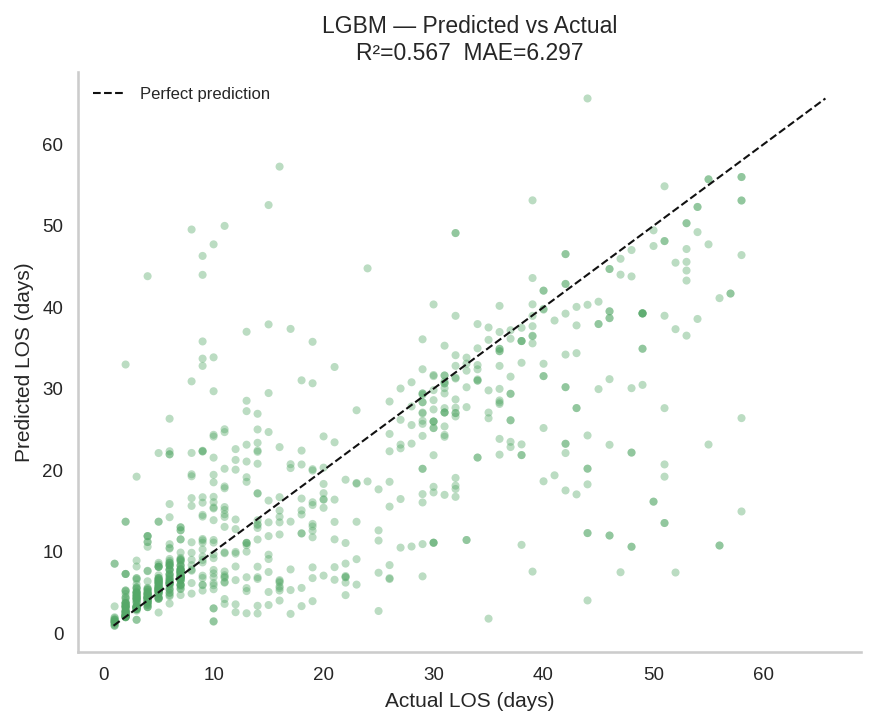

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/predicted_vs_actual_LGBM.png


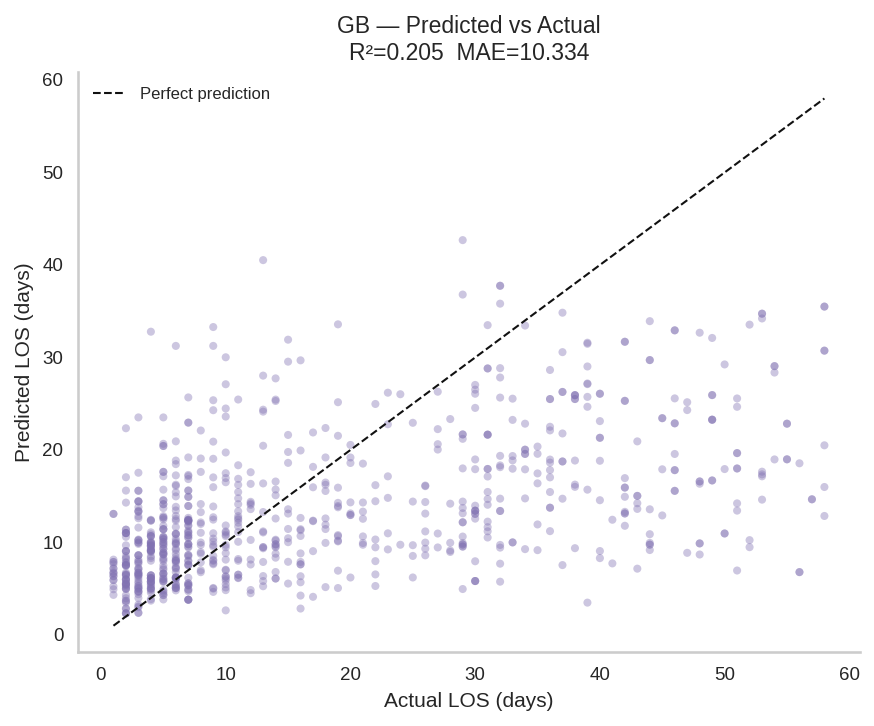

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/predicted_vs_actual_GB.png


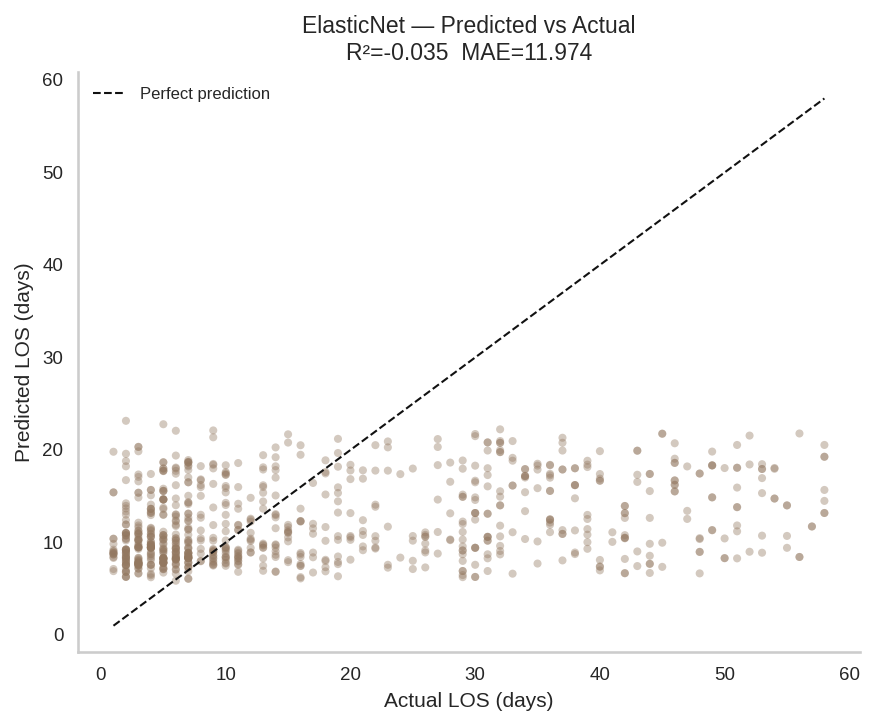

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/predicted_vs_actual_ElasticNet.png


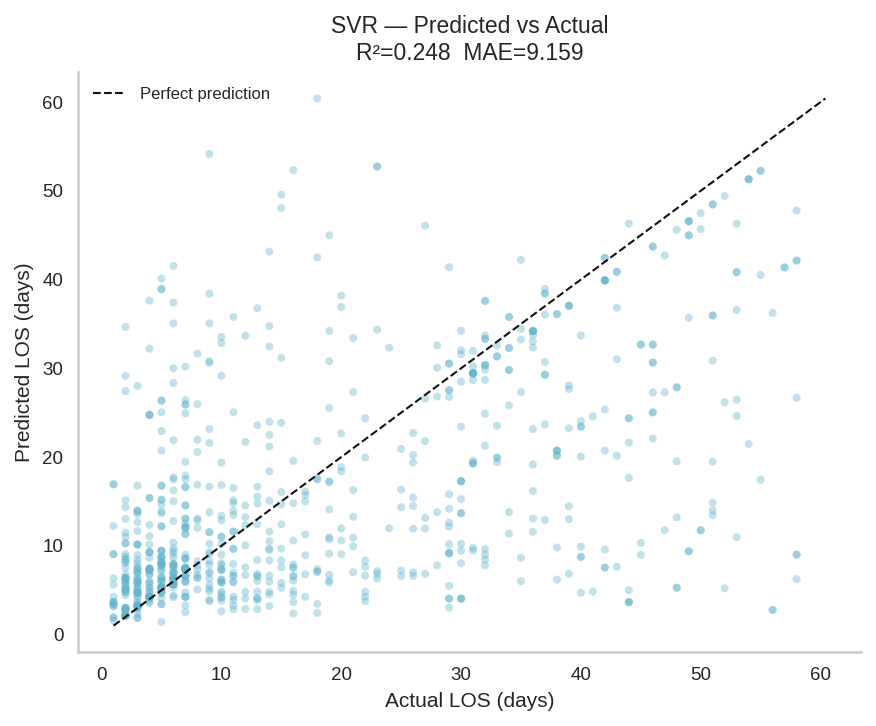

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/predicted_vs_actual_SVR.png


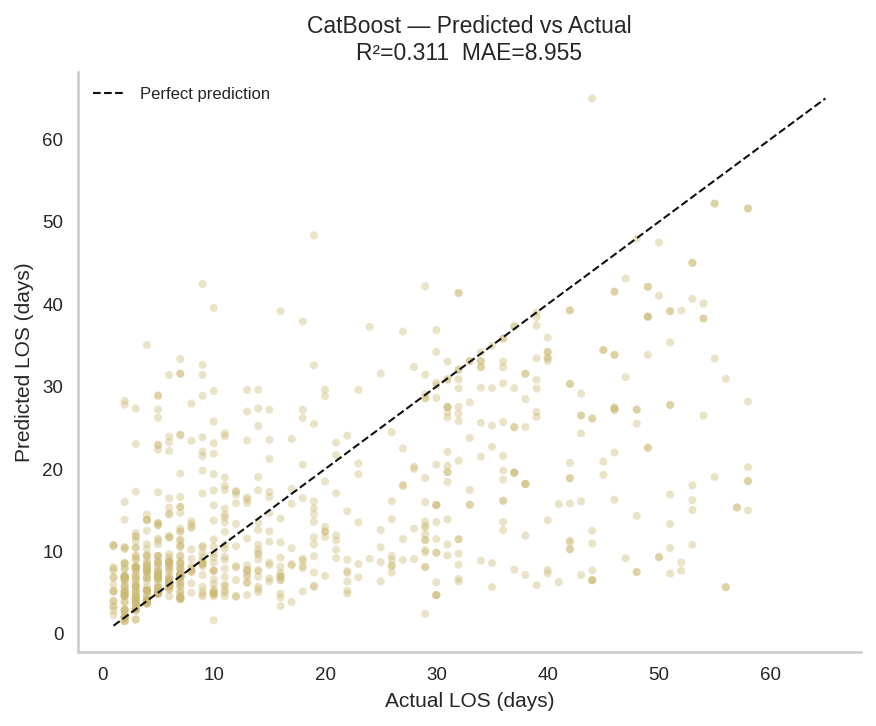

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/predicted_vs_actual_CatBoost.png


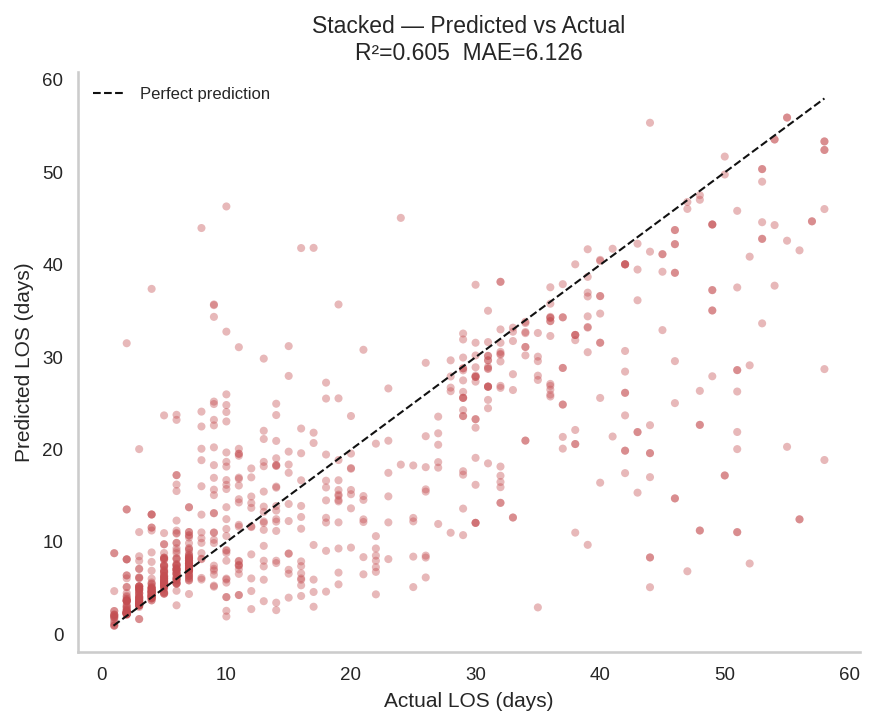

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/predicted_vs_actual_Stacked.png


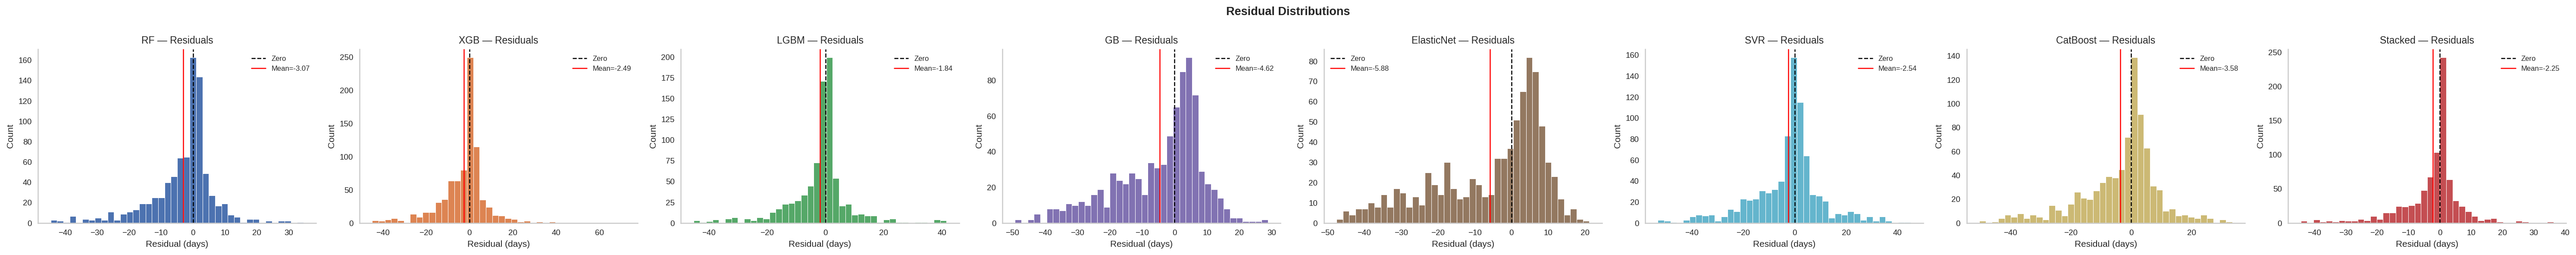

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/residual_distributions.png


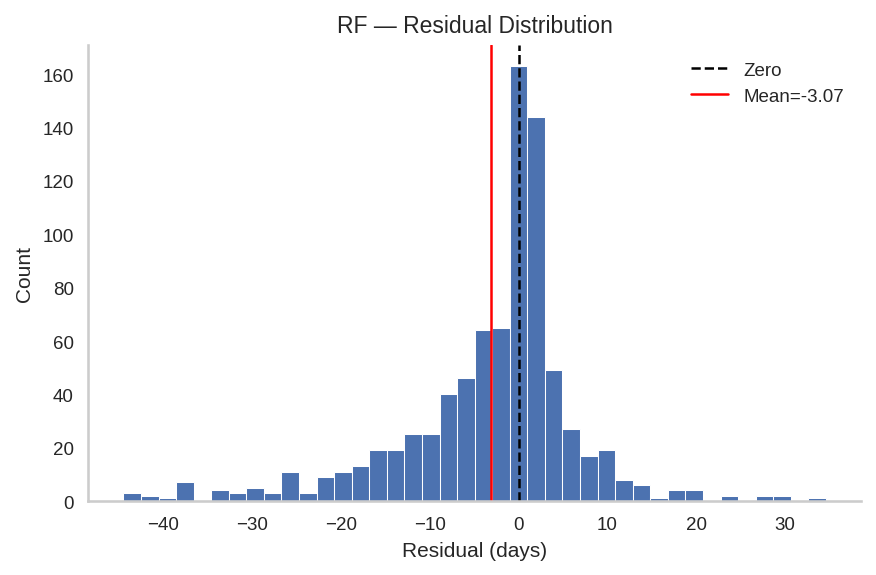

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/residuals_RF.png


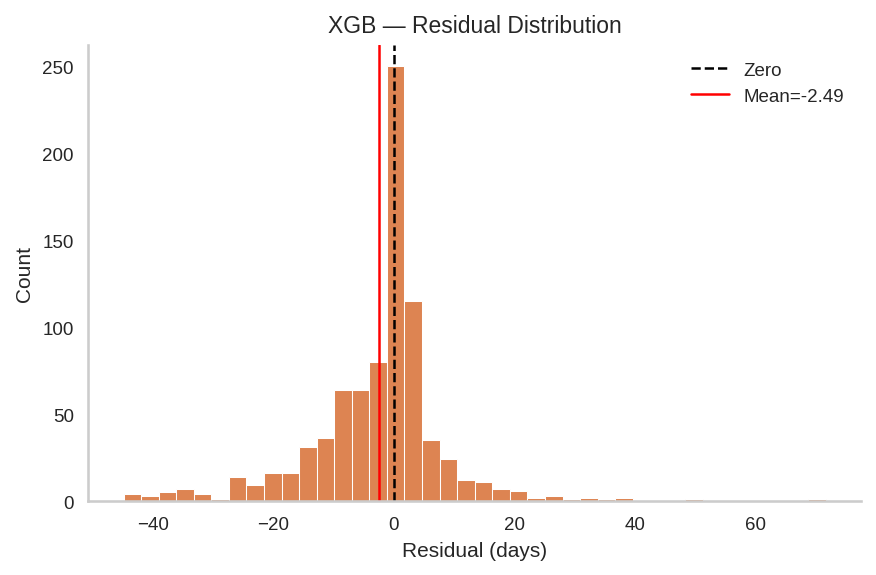

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/residuals_XGB.png


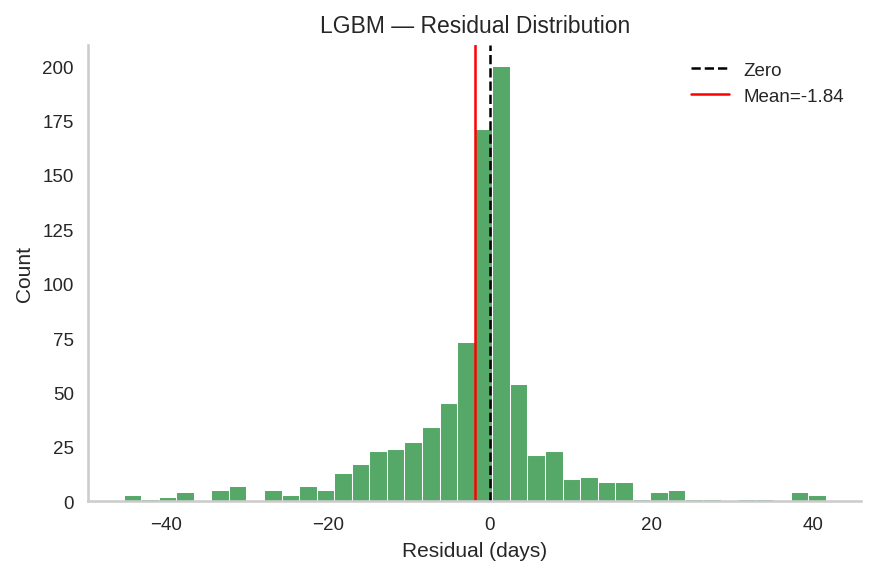

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/residuals_LGBM.png


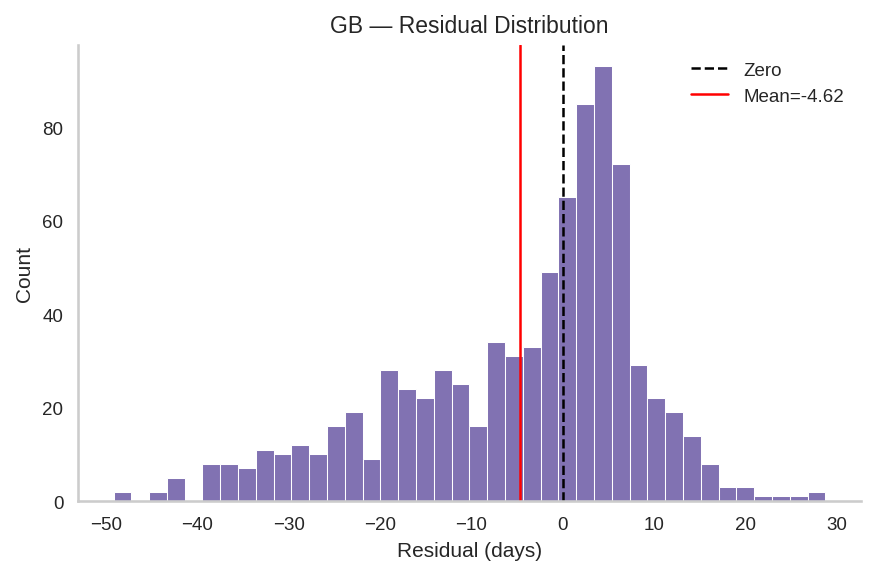

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/residuals_GB.png


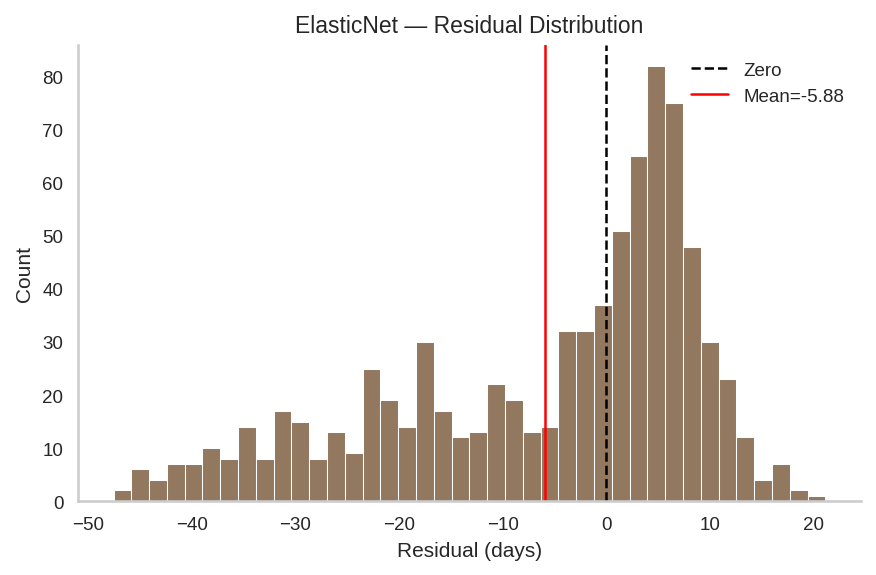

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/residuals_ElasticNet.png


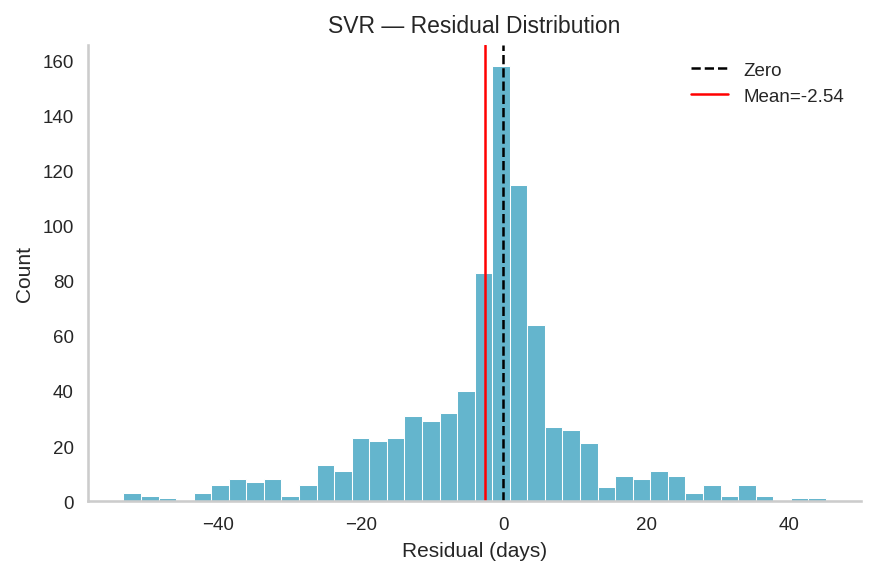

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/residuals_SVR.png


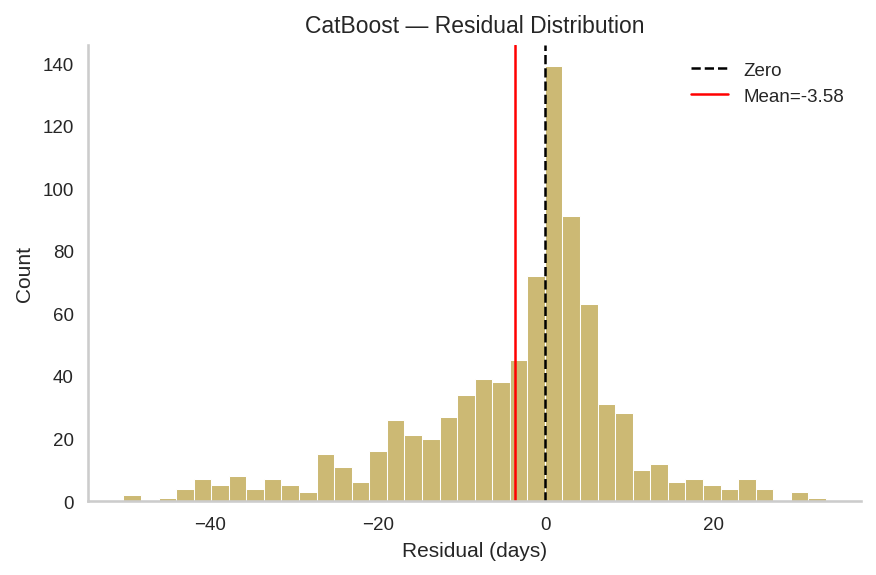

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/residuals_CatBoost.png


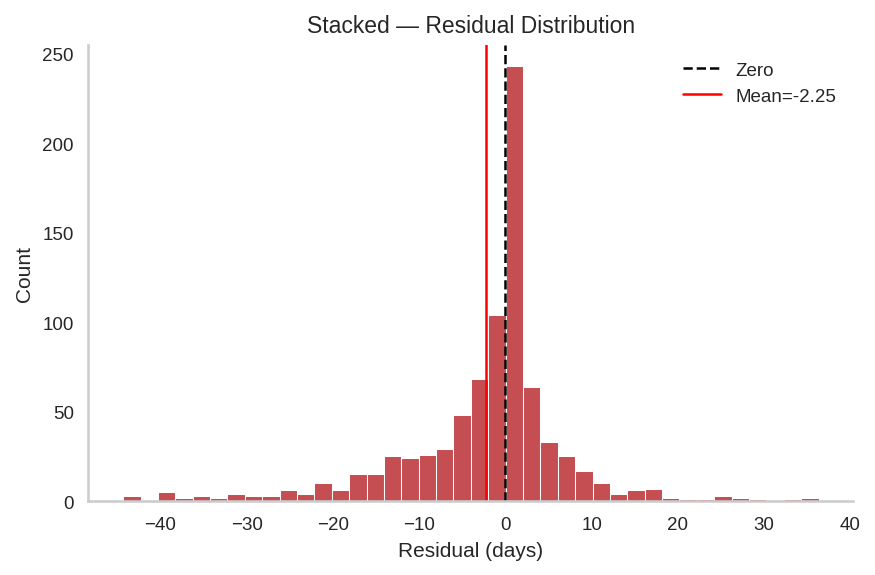

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/residuals_Stacked.png


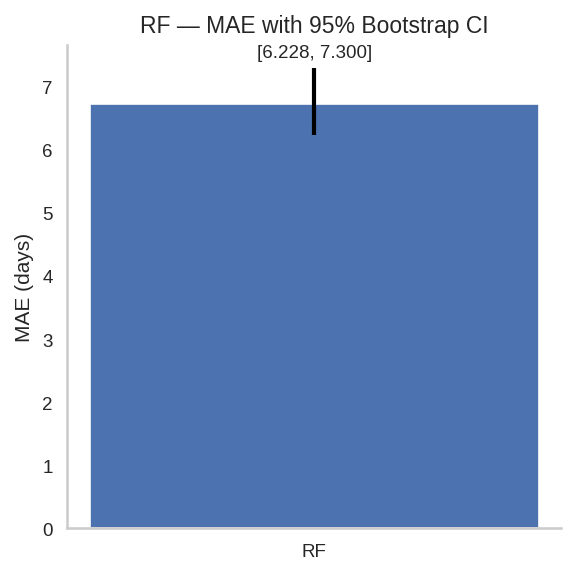

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/mae_ci_RF.png


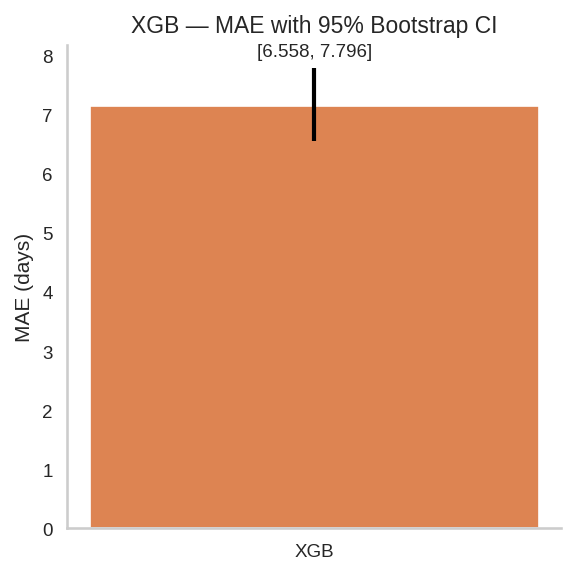

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/mae_ci_XGB.png


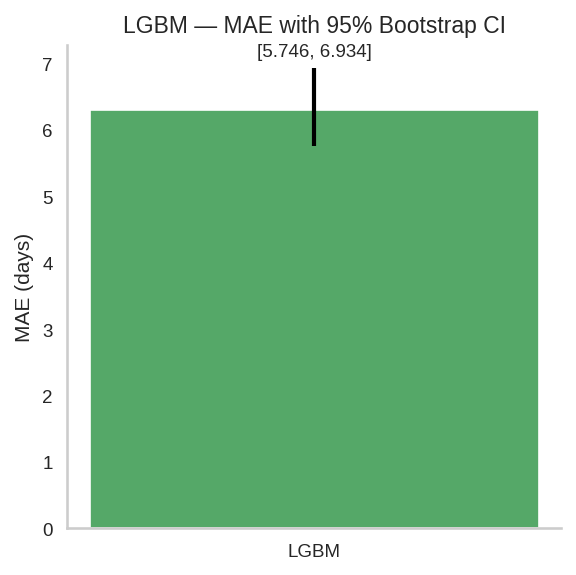

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/mae_ci_LGBM.png


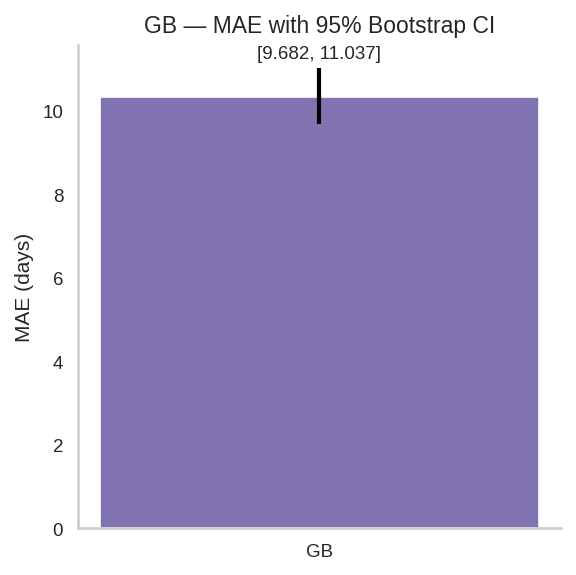

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/mae_ci_GB.png


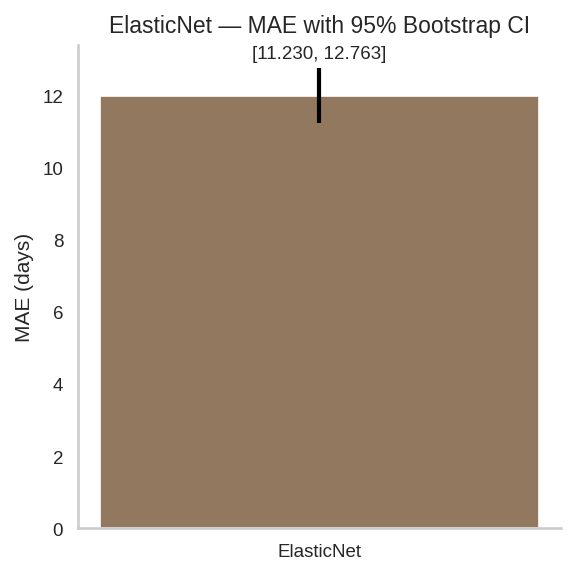

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/mae_ci_ElasticNet.png


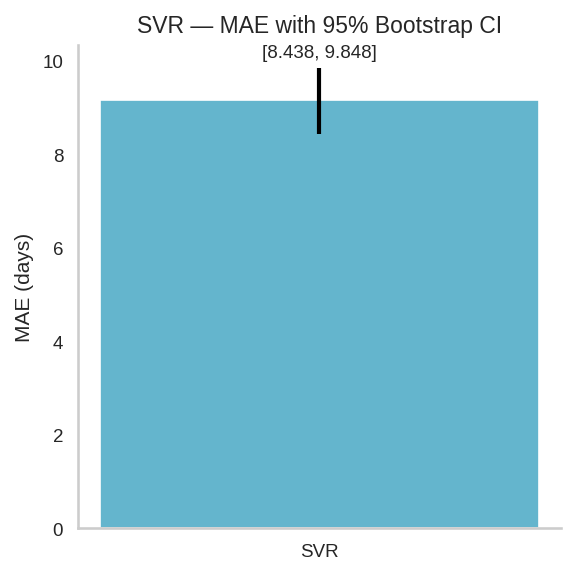

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/mae_ci_SVR.png


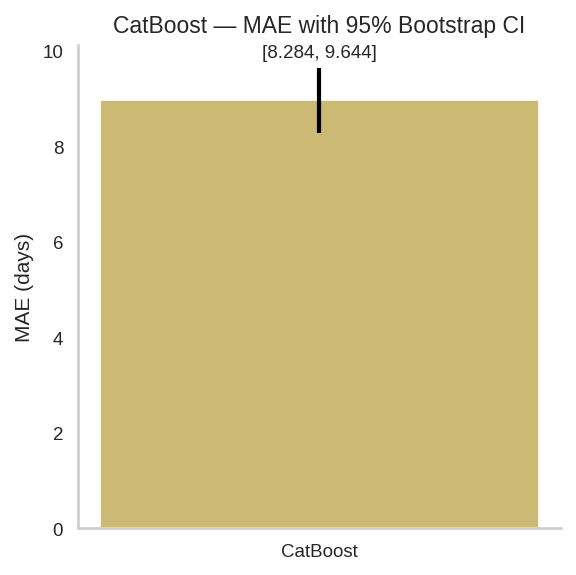

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/mae_ci_CatBoost.png


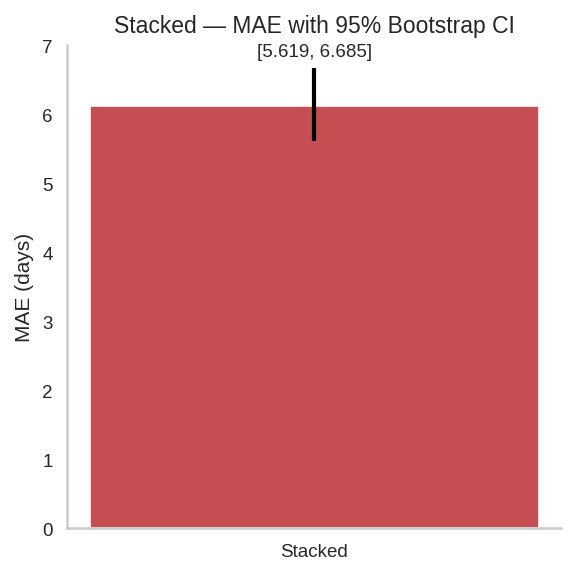

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/mae_ci_Stacked.png


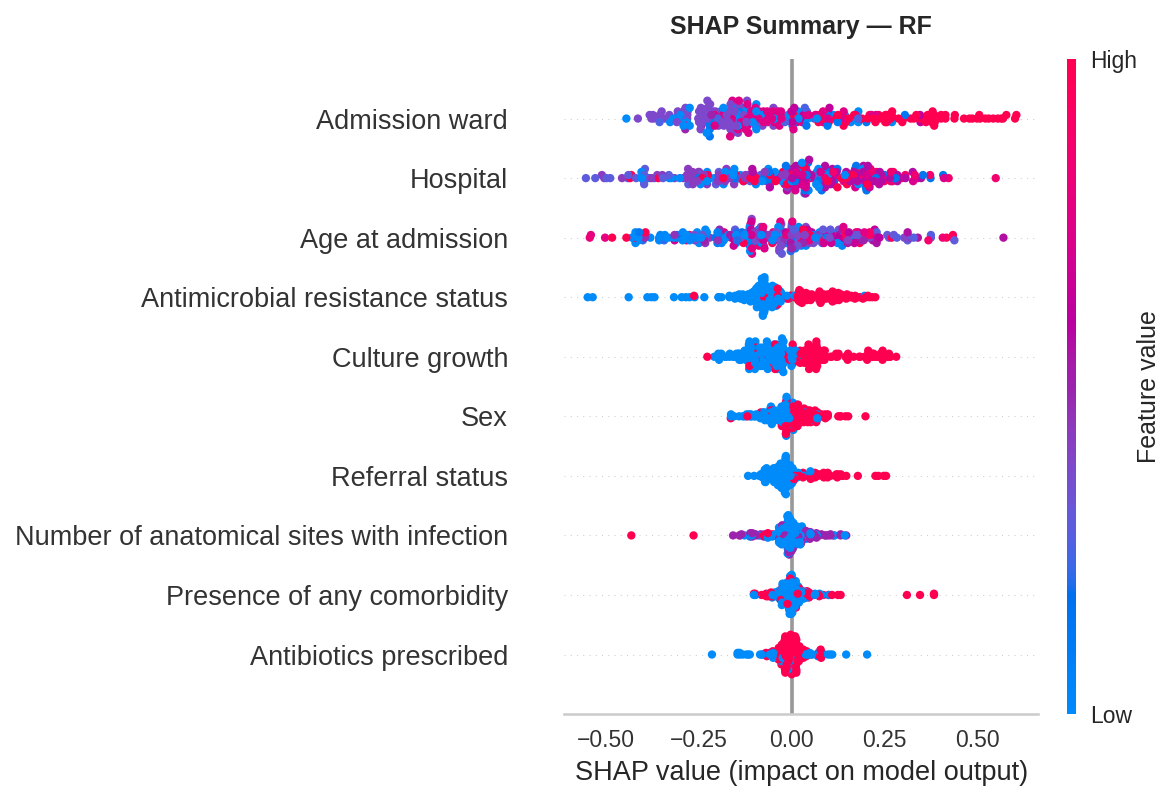

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/shap_summary_RF.png


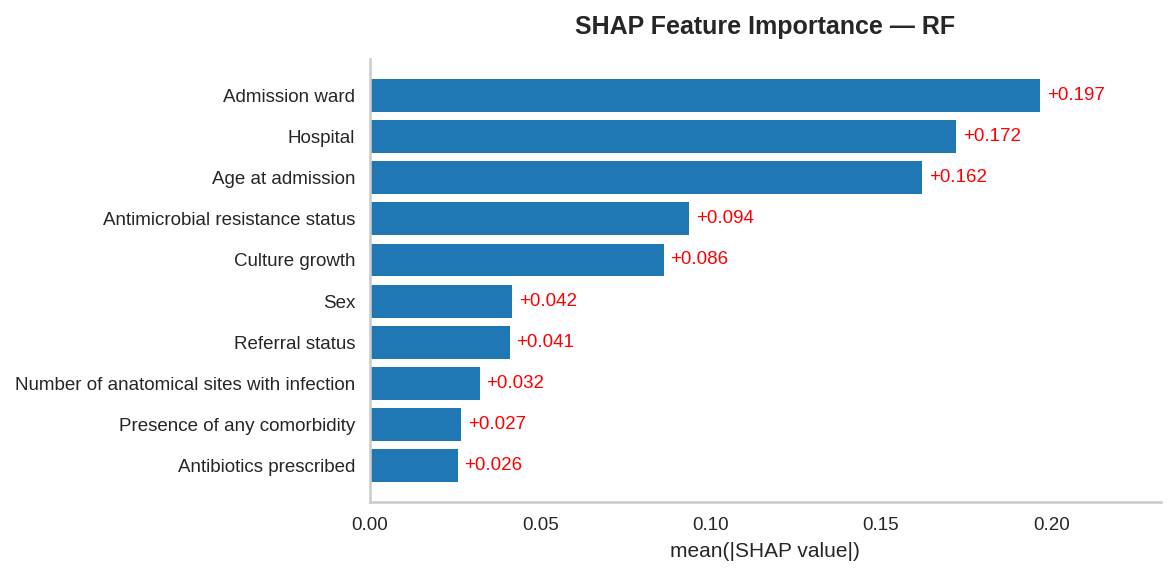

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/shap_importance_RF.png
SHAP failed for XGB: could not convert string to float: '[2.5285144E0]'


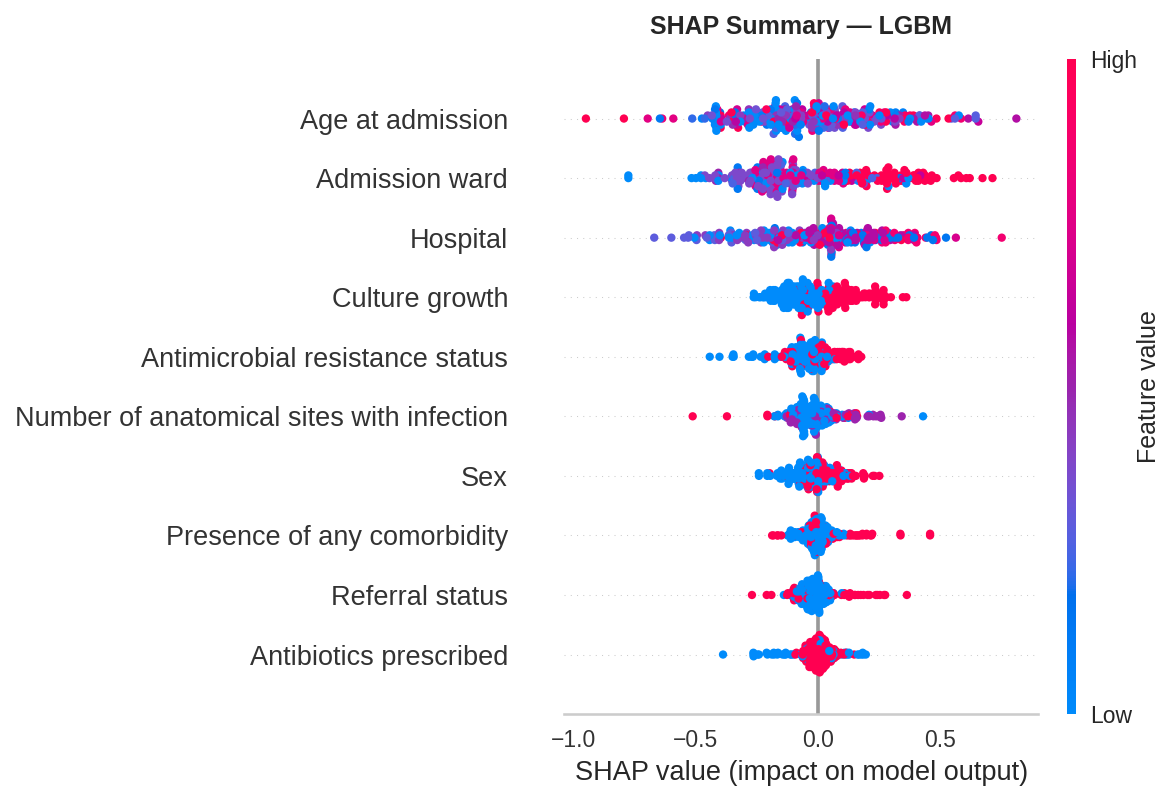

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/shap_summary_LGBM.png


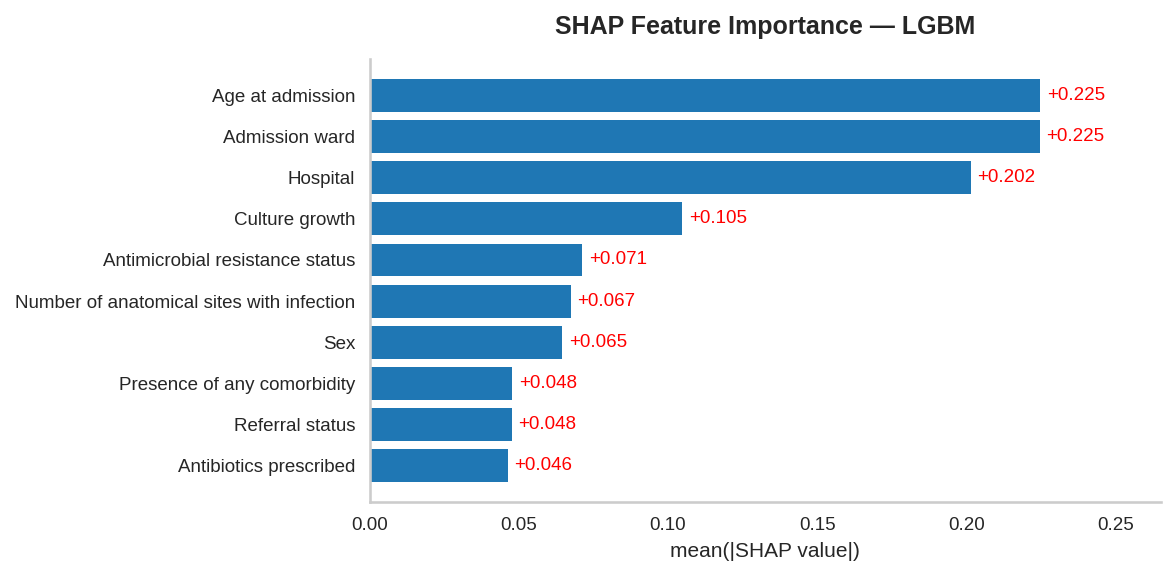

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/shap_importance_LGBM.png


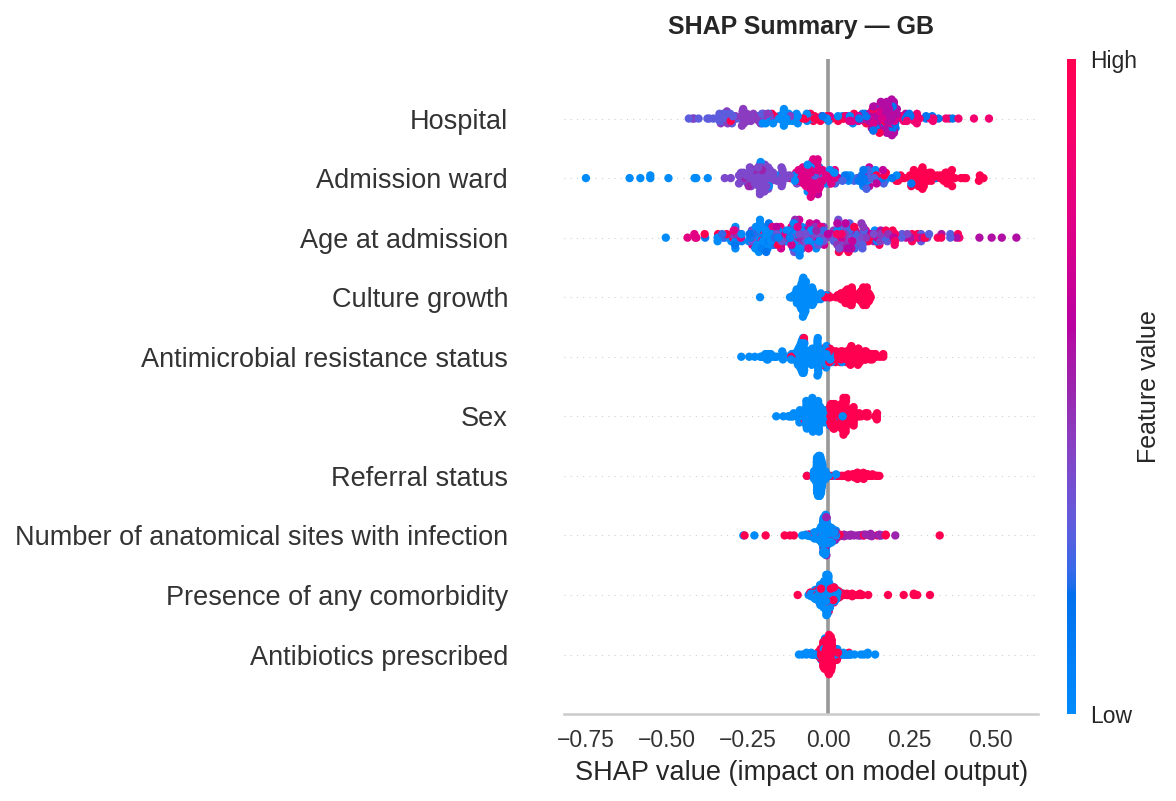

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/shap_summary_GB.png


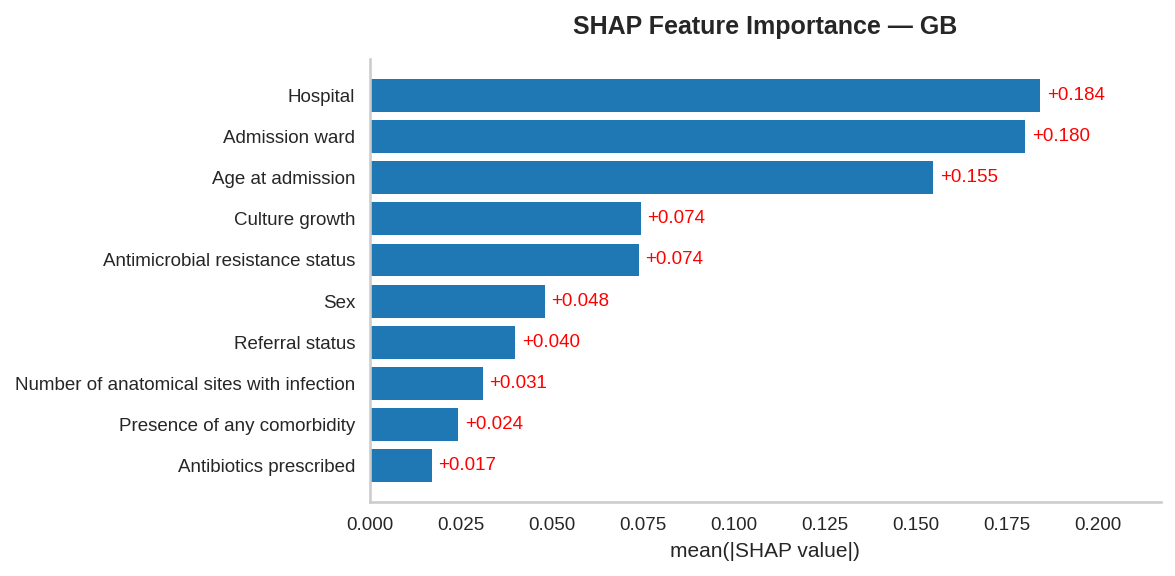

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/shap_importance_GB.png


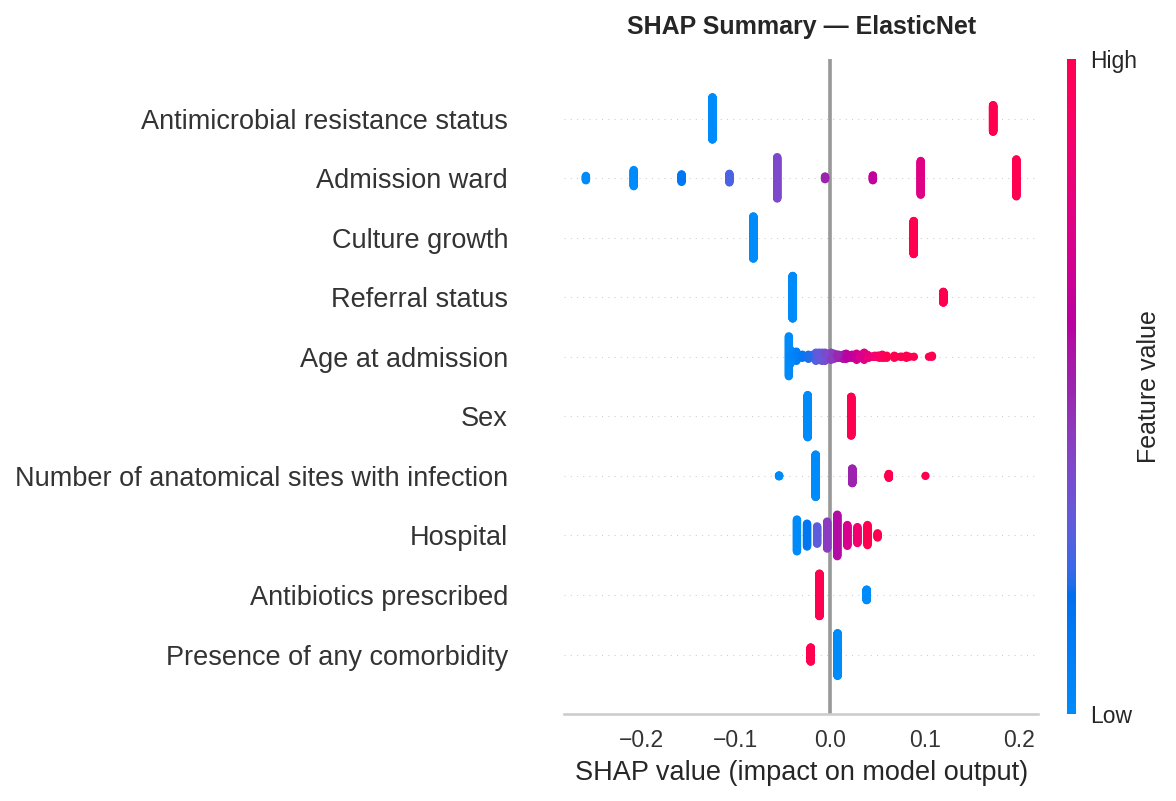

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/shap_summary_ElasticNet.png


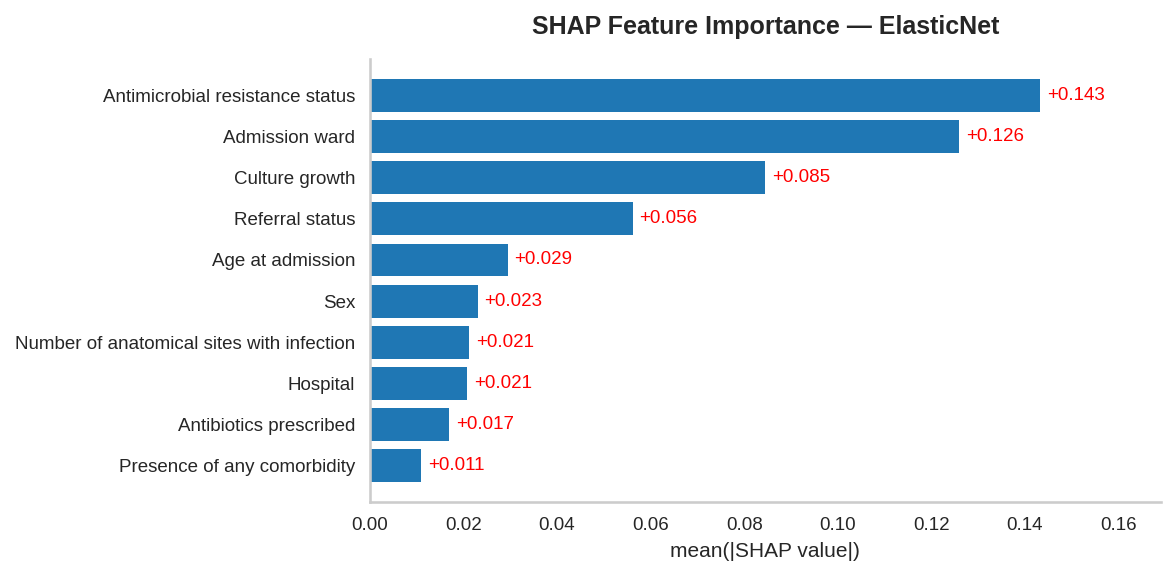

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/shap_importance_ElasticNet.png


  0%|          | 0/300 [00:00<?, ?it/s]

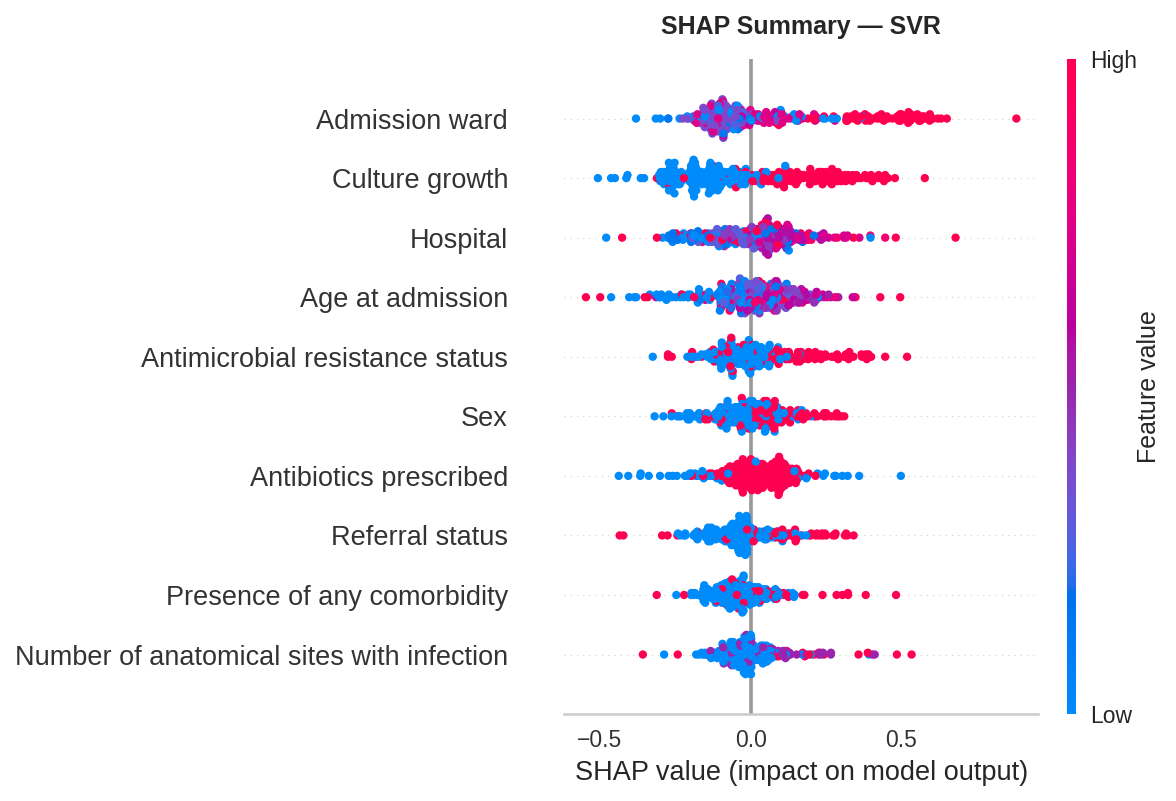

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/shap_summary_SVR.png


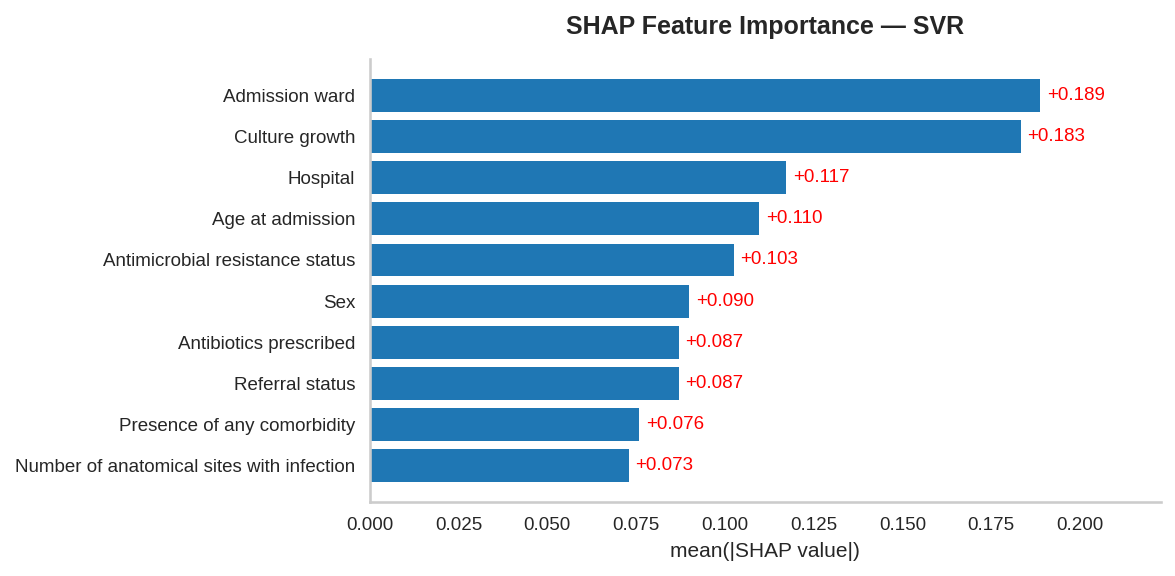

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/shap_importance_SVR.png


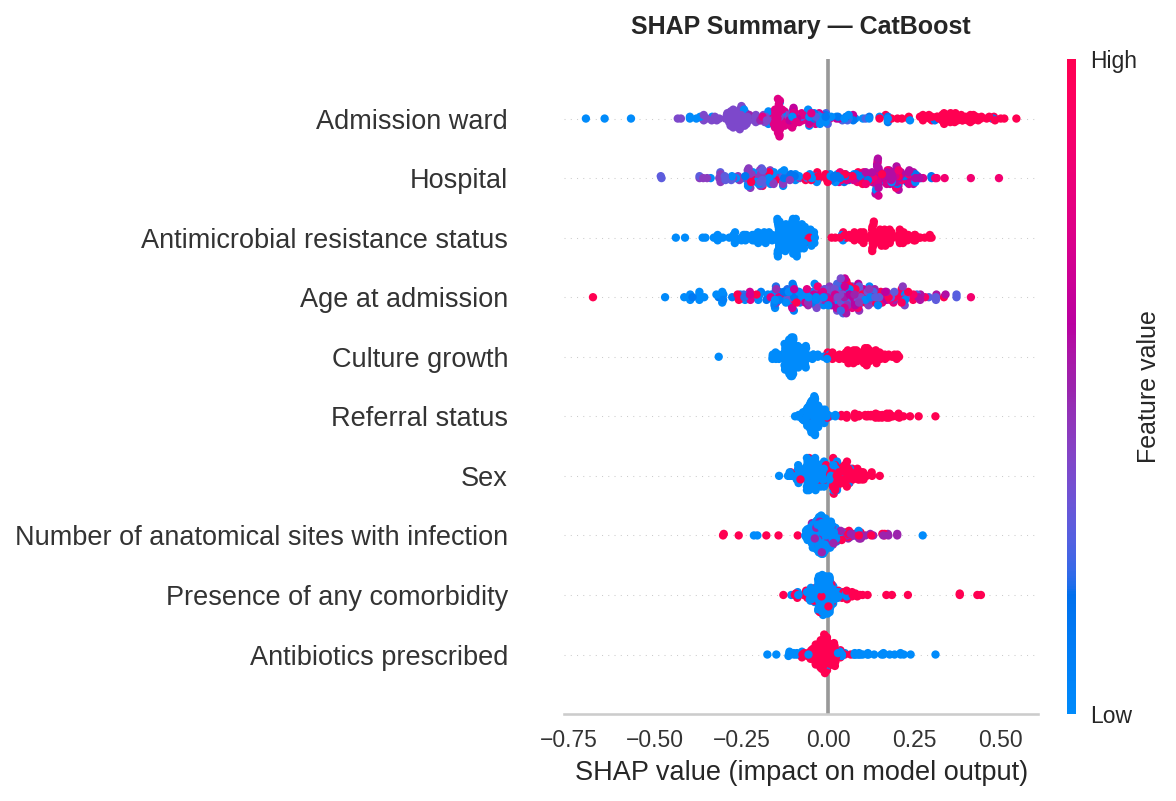

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/shap_summary_CatBoost.png


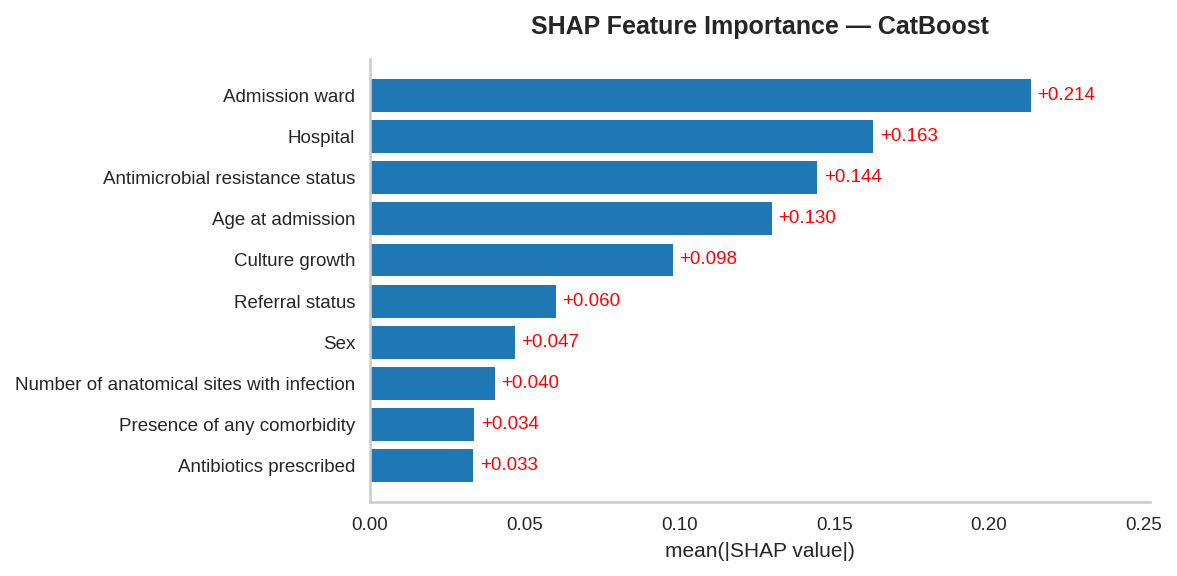

Saved: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/shap_importance_CatBoost.png

ALL OUTPUTS SAVED TO: /home/kyomukama/ACE/camonet/ML_Rerun/Outputs/ML_outputs/
  BEST_MODEL.joblib                                       1.1 KB
  BEST_MODEL_info.joblib                                  0.5 KB
  BEST_MODEL_summary.txt                                  0.7 KB
  best_model.joblib                                    4469.3 KB
  best_model_info.joblib                                  0.4 KB
  best_model_summary.txt                                  0.8 KB
  mae_ci_CatBoost.png                                    22.1 KB
  mae_ci_ElasticNet.png                                  21.5 KB
  mae_ci_GB.png                                          19.5 KB
  mae_ci_LGBM.png                                        20.0 KB
  mae_ci_RF.png                                          18.9 KB
  mae_ci_SVR.png                                         20.1 KB
  mae_ci_Stacked.png                            

<Figure size 800x550 with 0 Axes>

In [174]:
# Run the ML pipeline
%run -i "/home/kyomukama/ACE/Patient outcomes/HLOS/ML_developement/Scripts/ML_LOS_pipeline.py"

In [192]:
ml_data.shape

(4161, 11)

## table one


In [193]:
data.columns

Index(['age', 'num_infection_sites', 'sex', 'referral', 'cormobid_condition',
       'antibiotics_prescribed', 'growth1', 'Resistance', 'name_of_rrh',
       'ward', 'length_hosp_stay'],
      dtype='object')

In [ ]:

import pandas as pd
import numpy as np

df = ml_data.copy()

outcome = 'length_hosp_stay'

df[outcome] = pd.to_numeric(df[outcome], errors="coerce")

# Identify categorical variables
categorical_vars = [
    col for col in df.columns
    if df[col].dtype in ["object", "category", "bool"]
]

# Add numeric-coded categorical variables explicitly
categorical_vars += [
    "sex", "hospital"
]  # Replace/add names using your actual column names

categorical_vars = list(dict.fromkeys(
    col for col in categorical_vars
    if col in df.columns and col != outcome
))

# Identify continuous variables
continuous_vars = [
    col for col in df.select_dtypes(include="number").columns
    if col not in categorical_vars and col != outcome
]

results = []

# Overall summary
results.append({
    "Variable": "Overall",
    "Category": "All patients",
    "N": df[outcome].count(),
    "Percentage (%)": 100,
    "Mean LOS": df[outcome].mean(),
    "SD": df[outcome].std()
})

# Categorical variables: actual values and frequencies
for var in categorical_vars:

    for category, group in df.groupby(var, dropna=False, sort=True):

        los = group[outcome].dropna()

        results.append({
            "Variable": var,
            "Category": "Missing" if pd.isna(category) else str(category),
            "N": len(group),
            "Percentage (%)": len(group) / len(df) * 100,
            "Mean LOS": los.mean(),
            "SD": los.std()
        })

# Continuous variables: one row each
for var in continuous_vars:

    results.append({
        "Variable": var,
        "Category": f"Mean (SD): {df[var].mean():.2f} ({df[var].std():.2f})",
        "N": df[var].count(),
        "Percentage (%)": np.nan,
        "Mean LOS": df[outcome].mean(),
        "SD": df[outcome].std()
    })

# Create table
table1 = pd.DataFrame(results)

# Format
table1["Percentage (%)"] = table1["Percentage (%)"].round(1)
table1["Mean LOS"] = table1["Mean LOS"].round(2)
table1["SD"] = table1["SD"].round(2)

display(table1)

# Export
table1.to_excel("Table1_Length_of_Stay.xlsx", index=False)


,Variable,Category,N,Percentage (%),Mean LOS,SD
0,Overall,All patients,4161,100.0,17.83,16.20
1,Sex,0.0,2152,51.7,17.01,15.98
2,Sex,1.0,2009,48.3,18.70,16.40
3,Referral status,0.0,3257,78.3,17.37,16.07
4,Referral status,1.0,904,21.7,19.49,16.55
5,Presence of any comorbidity,0.0,3062,73.6,17.81,15.97
6,Presence of any comorbidity,1.0,1099,26.4,17.88,16.83
7,Antibiotics prescribed,0.0,921,22.1,18.77,17.23
8,Antibiotics prescribed,1.0,3240,77.9,17.56,15.89
9,Culture growth,0.0,2127,51.1,13.46,13.64
